---
title: "The Graetz–Nusselt problem: the constants Graetz could not compute"
description: "The developing thermal boundary layer in a tube, solved as a 2-D PDE, and the two amplitudes Graetz declared out of reach and calibrated out of his own apparatus instead."
categories: [sec:A, struct:S6, tier:T0, data:tier1, phase:liquid]
date: 2026-08-05
---

# The Graetz–Nusselt problem: the constants Graetz could not compute

**Catalog ID:** `A3.15` · **Structure:** `S6` (2-D PDE) · **Tier:** T0

Leo Graetz did not set out to found a branch of convective heat transfer. He was
trying to measure the thermal conductivity of liquids, and the problem now named
after him is the calculation he needed in order to read his own instrument.

The calculation stopped one step short. He obtained the eigenvalues, and then
wrote that the *amplitudes* multiplying them would need "an exhaustive
investigation of the function $V(r,\beta,R)$, which is probably not simple",
so for physical purposes he determined them **experimentally, as constants of the
apparatus**.

This page computes them, and then asks what that does to his measurements. The
answer is not the one the framing suggests.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.01.2"  # replaced by the release tag at publication
PYMRM = ">=3.3.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "A3.15-graetz-nusselt"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
import time
import warnings
from math import gamma

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from scipy.optimize import brentq, fsolve
from scipy.special import jn_zeros
from gallery_utils import load_data, load_meta, cite_data, Claims
from model import (GraetzTube, decay, V_profile, eigen, amplitudes,  # this page's model.py
                   series_coeffs, theta_series, invert)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])
BREAK = []


def brk(row, metric, broken):
    """One injected defect: ``broken`` is what claim ``metric`` becomes with it."""
    caught = claims.breaks(row, metric, broken)
    BREAK.append((row, metric, claims[metric], float(broken), caught))
    return caught


_SOLVES = {}


def solve2d(**kw):
    """The 2-D Newton solve for the given GraetzTube arguments, computed once."""
    key = tuple(sorted(kw.items(), key=lambda kv: kv[0]))
    if key not in _SOLVES:
        tube = GraetzTube(**kw)
        _SOLVES[key] = (tube, tube.solve())
    return _SOLVES[key]

## Background

*Everything quoted from the paper below is in the original German with a
translation. Nothing load-bearing rests on a translation alone.*

Graetz's apparatus (his §2) is a flow calorimeter. Liquid at temperature $T_1$
flows under a constant head through a narrow brass tube whose wall is held at
the temperature $T_0$ of running cooling water; the outflow temperature $U$ and
the weight $G$ collected in one minute are measured. From $T_0$, $T_1$, $U$, $G$
and the tube length $l$ the conductivity follows, *if* you can solve for the
temperature field inside the tube.

That is the Graetz problem. He solves it twice.

**First with a flat velocity profile** (§3), which gives Bessel functions and the
classical $J_0$ zeros. He then says plainly that this will not do:

> "Die Annahme jedoch, dass die Flüssigkeit in jedem Punkte der Röhre dieselbe
> mittlere Geschwindigkeit $\alpha$ habe, ist weder in der Natur erfüllt, noch
> wie die Berechnung zeigt, zur Vereinfachung erlaubt."

*(The assumption that the liquid has the same mean velocity $\alpha$ at every
point of the tube is neither fulfilled in nature nor, as the calculation shows,
permissible even as a simplification.)*

**Then with the Poiseuille profile**, which is the problem that carries his name.
The radial equation is no longer Bessel's, and the eigenfunctions are, as he
notes, an extension of the Bessel functions that he expects "may perhaps possess
independent mathematical interest".

Two things make this worth a page rather than a footnote:

1. It is the ancestor of every entrance-length correlation in heat and mass
   transfer, and the asymptotic Nusselt number of a tube at constant wall
   temperature is the first eigenvalue of this problem squared and halved.
2. **The paper contains measurements** (six liquids, three pressure heads), and
   it contains a calibration step whose weakness is invisible from inside the
   paper and obvious from outside it.

## The published model

**The equation** (journal page 87, read from the page image):

$$
2\alpha\left(1 - \frac{r^{2}}{R^{2}}\right)\frac{\partial u}{\partial z}
= a^{2}\left(\frac{\partial^{2}u}{\partial r^{2}} + \frac{1}{r}\frac{\partial u}{\partial r}\right),
\qquad a^{2} = \frac{k}{\varrho C},
$$

with $u$ measured from the wall temperature, $u = T_1$ at $z = 0$ and $u = 0$ at
$r = R$. $\alpha$ is the **mean** velocity, so $2\alpha(1-r^2/R^2)$ is Poiseuille
flow. Axial conduction is present in his plug-flow equation on page 83 and
dropped here; §7 of the validation checks that.

**The separation** $u = A\,e^{-(a^{2}/2\alpha)\beta^{2}z}V$ gives

$$
\frac{\mathrm{d}^{2}V}{\mathrm{d}r^{2}} + \frac{1}{r}\frac{\mathrm{d}V}{\mathrm{d}r}
+ \beta^{2}\left(1 - \frac{r^{2}}{R^{2}}\right)V = 0,
\qquad V(r,\beta,\infty) = J_{0}(\beta r),
$$

and the eigenvalues are the roots $\mu = \beta R$ of $V(R,\beta,R) = 0$. Graetz
expands $V$ in powers of $x = \beta r$ and prints the resulting polynomial in
$\mu$ and its first two roots.

**The measurable** (page 88) is the mean outlet temperature

$$
U = T_{1}\sum_{i} p_{i}\,
    \exp\!\left(-\frac{a^{2}\mu_{i}^{2}\pi l \varrho}{2G}\right),
$$

and since $a^{2} = k/(\varrho C)$ the density cancels, so **the observations give
$k/c$ directly**, which is what his tables report. The tube radius cancels too,
a point he makes explicitly on page 82.

**And then the step this page is about** (page 88):

> "Darin sind die $p_i$ Constanten, die ausser von den $\mu_i$ nur von $R$
> abhängen. Es wäre natürlich von wesentlichem Vortheil, wenn sich die $p_i$
> bestimmt durch $R$ und $\mu_i$ ausdrücken liessen. Indess gehört dazu eine
> eingehende Untersuchung der Function $V(r,\beta,R)$, die wahrscheinlich nicht
> einfach ist, die aber als Erweiterung der Bessel'schen Function vielleicht
> selbstständiges mathematisches Interesse besitzt. Für physikalische Zwecke
> lassen sich dagegen die $p_i$ sehr einfach als Constanten des Apparates
> experimentell bestimmen."

*(Therein the $p_i$ are constants which, besides on the $\mu_i$, depend only on
$R$. It would of course be of essential advantage if the $p_i$ could be expressed
definitely through $R$ and $\mu_i$. However, that requires an exhaustive
investigation of the function $V(r,\beta,R)$, which is probably not simple, but
which as an extension of the Bessel function may perhaps possess independent
mathematical interest. For physical purposes, on the other hand, the $p_i$ can
very simply be determined experimentally as constants of the apparatus.)*

He then keeps two terms, and fits $p_1$, $p_2$ **and** $k/c$ to three runs of one
liquid at three pressure heads. Three constants, three observations.

## Parameters and assumptions

**His:** steady state; fully developed Poiseuille flow from $z = 0$; constant
wall temperature; constant $k$, $\varrho$, $c$ over the run; no axial conduction
in the Poiseuille case; the measured outflow temperature equals the cross-section
mean of $u$ at $z = l$; and, for the working formula, two terms of the series
suffice, "Das zweite Glied macht noch etwa 3 Proc. in dem Werthe von $k$ aus"
(*the second term still accounts for about 3 per cent in the value of $k$*).

**Ours:** the same, written in dimensionless form. With $s = r/R$ and

$$
x \;=\; \frac{a^{2}z}{2\alpha R^{2}} \;=\; \frac{a^{2}\pi z}{2\dot V}
\;=\; \frac{(k/c)\,\pi z}{2G},
$$

the whole problem loses every parameter:

$$
(1-s^{2})\frac{\partial\theta}{\partial x}
= \frac{1}{s}\frac{\partial}{\partial s}\!\left(s\frac{\partial\theta}{\partial s}\right)
+ \frac{1}{\mathrm{Pe}^{2}}\frac{\partial^{2}\theta}{\partial x^{2}},
\qquad \theta(0,s) = 1,\quad \theta(x,1) = 0,
$$

with $\theta = (T-T_0)/(T_1-T_0)$ and $\mathrm{Pe} = 2\alpha R/a^{2}$ the axial
Péclet number. Setting $1/\mathrm{Pe}^{2} = 0$ is Graetz's equation exactly.
$x$ is twice the Graetz coordinate $x^{*} = z/(D_{h}\mathrm{Re}\,\mathrm{Pr})$
used in the modern literature.

The **cup-mean** (flow-weighted) outlet temperature is what a collected sample
measures:

$$
\theta_{\text{cup}}(x) = 4\!\int_{0}^{1}(1-s^{2})\,\theta\,s\,\mathrm{d}s
= \sum_{i} p_{i}\,e^{-\mu_{i}^{2}x}.
$$

Note that Graetz's own page-88 formula integrates $V$ against $r\,\mathrm{d}r$
and divides by $R^{2}\pi$: that is the **area** mean, not the cup mean. §8f
measures what the difference is worth.

## The data

Two files. `graetz-1882-observations.csv` is all the runs of his §4: six liquids,
the three temperatures, the collected weight, and the $k/c$ and $k$ he computes
from them. `graetz-1882-printed-constants.csv` is every constant printed in
§§2–4 with the journal page it is on, including the series coefficients and the
two fitted amplitudes.

**These are measurements**, which makes this one of the few tier-1 pages in the
gallery, but the $k/c$ column is *derived*, by his two-term formula with his
two fitted amplitudes. The raw measurement is the four temperature-and-mass
columns, and this page inverts those independently.

**Read the sidecars before using either file.** They record: three rows flagged
because the fit that uses them has zero degrees of freedom; the internal
consistency checks (`T = (T₁+U)/2`, `k = c·(k/c)`) and the one liquid that fails
the second; and three printed defects in the constants file. No other page's
dataset is loaded.

In [3]:
obs = load_data("graetz-1882-observations.csv", page=PAGE)
con = load_data("graetz-1882-printed-constants.csv", page=PAGE)
obs_meta = load_meta("graetz-1882-observations.csv", page=PAGE)
con_meta = load_meta("graetz-1882-printed-constants.csv", page=PAGE)
C = dict(zip(con.quantity, con.value))
# journal page each constant is printed on, as an integer, so that statements
# like "N pages earlier" are computed from the file rather than typed
PAGE_OF = {q: int(str(s).split()[-1]) for q, s in zip(con.quantity, con.source)}

obs["theta"] = (obs.T_out_C - obs.T_bath_C) / (obs.T_in_C - obs.T_bath_C)
CAL = obs[obs.calibration_row == 1].reset_index(drop=True)

print(f"{len(obs)} runs, {obs.liquid.nunique()} liquids, "
      f"{len(con)} printed constants")
print(obs.groupby("liquid", sort=False)
         .agg(runs=("theta", "size"), G_min=("mass_flow_g_min", "min"),
              G_max=("mass_flow_g_min", "max"), theta_min=("theta", "min"),
              theta_max=("theta", "max")).to_string())
print(f"\n{cite_data(obs_meta)}")


def mean_T_check(t_mean):
    """|(T_in + T_out)/2 - printed T| per row, for a given reading of the mean."""
    return (t_mean - obs.T_mean_C_printed).abs()


# the two integrity checks the tables pay for, both stated in the sidecar
print("\nintegrity check 1:  T = (T_in + T_out)/2, which the paper states on p. 90")
dT = mean_T_check(0.5 * (obs.T_in_C + obs.T_out_C))
N_TMEAN_EXACT = claims.count("T_mean_rows_within_0p02", dT.values, 0.02, above=False,
                             min_margin=1e-3, relative=False,
                             note="rows with |(T_in+T_out)/2 - T| below 0.02 K; margin in K")
print(f"   exact in {N_TMEAN_EXACT} of {len(obs)} rows; "
      f"worst residual {dT.max():.2f} K "
      f"({int((obs.calibration_row[dT > 0.02] == 1).sum())} of the "
      "offenders are the calibration rows, which are means of five observations)")
print("\nintegrity check 2:  k = c * (k/c)")
for liq, g in obs.groupby("liquid", sort=False):
    imp = g.k_printed / g.k_over_c_printed
    stated = g.specific_heat.iloc[0]
    flag = ("" if (pd.isna(stated) or abs(imp.mean() / stated - 1) < 0.01)
            else f"   <-- {abs(imp.mean() / stated - 1) * 100:.1f} % gap")
    print(f"   {liq:11s} stated c = {stated!s:>5}   implied {imp.mean():.4f} "
          f"+/- {imp.std():.4f}{flag}")
print("   turpentine is a printed slip in one of the two numbers, not scatter;")
print("   the page works in k/c throughout, so nothing here depends on it.")

# the three flagged rows, up front
print("\nthe three rows Graetz fitted p1, p2 and k/c to (his stars, p. 91):")
print(CAL[["pressure_head", "T_in_C", "T_out_C", "T_bath_C", "mass_flow_g_min",
           "theta", "k_over_c_printed"]].to_string(index=False))
print(f"   flow range {CAL.mass_flow_g_min.max()/CAL.mass_flow_g_min.min():.2f}x, "
      "three constants, three observations -> zero degrees of freedom")

51 runs, 6 liquids, 37 printed constants
            runs    G_min    G_max  theta_min  theta_max
liquid                                                  
water         13   8.6320  36.4430   0.273514   0.682817
cuso4         11  13.8571  46.6320   0.431746   0.745387
alcohol        7   3.1790  17.3435   0.078408   0.580882
nacl           7  25.0960  36.5595   0.590014   0.673511
znso4          8  32.7445  37.2430   0.660529   0.681419
turpentine     5  13.5690  19.5123   0.506574   0.606418

Graetz, L. (1882) — Annalen der Physik 254(1) 79-94 — doi:10.1002/andp.18822540106 — table

integrity check 1:  T = (T_in + T_out)/2, which the paper states on p. 90
   exact in 44 of 51 rows; worst residual 0.51 K (3 of the offenders are the calibration rows, which are means of five observations)

integrity check 2:  k = c * (k/c)
   water       stated c =   nan   implied 1.0019 +/- 0.0006
   cuso4       stated c =  0.95   implied 0.9494 +/- 0.0007
   alcohol     stated c =  0.62   implied 0.6197

## PyMRM implementation

The 2-D solve produces the first eigenvalue *and* its amplitude without ever
forming an eigenfunction, so it is an independent witness against the series route in §3
of the validation. It lives in `GraetzTube` in this page's `model.py`.

- **`construct_div(..., nu=1)` on the radial axis**: cylindrical geometry, which
  is what puts the $\tfrac{1}{s}\partial_s(s\,\partial_s)$ in the equation. The
  axial axis is `nu=0`, Cartesian. The state is laid out `(n_z, n_r)`, the
  marching axis first.
- **Every `bc` carries its physical equation in a comment**, because `a` is
  written on the *outward* normal and therefore means different things at the two
  ends of an axis.
- **First-order upwind is not good enough here.** The exact problem has no axial
  diffusion at all, so upwind numerical diffusion is pure error and it converges
  at first order (§3 and the break table measure it). The axial convective face
  values are van Leer TVD. Because the limiter makes the equations nonlinear, the
  solve is Newton with the exact Jacobian of the limited flux from
  `ConvFluxTVD`, `newton(damping="monotone", stagnation=True)`, from
  $\theta = 1$ everywhere. The conduction operators are linear and assembled
  once in the constructor; each Newton iteration only evaluates the limited
  flux and factorises.
- **A second solver route for the same discrete equations**, `solve_deferred`:
  one LU of the first-order upwind operator, the limiter correction lagged in
  the right-hand side and the update relaxed by $\omega$. The cell below
  measures what it needs: at $\omega = 1$ the sweeps settle into a period-two
  cycle instead of converging, and below 1 they converge to the Newton field.
  It is the faster route on these grids (the times are printed), so it is the
  natural check; it is not used for any published number.

In [4]:
PUB = dict(n_z=600, n_r=128)
NEWTON_TOL = 1e-11          # GraetzTube.solve default; theta is of order one
t0 = time.perf_counter()
TUBE, SOL = solve2d(**PUB)
T_NEWTON = time.perf_counter() - t0
t0 = time.perf_counter()
DEF = TUBE.solve_deferred(omega=0.6)
T_DEF = time.perf_counter() - t0
ROUTE_GAP = float(np.max(np.abs(DEF["theta"] - SOL["theta"])))
print(f"published grid n_z = {PUB['n_z']}, n_r = {PUB['n_r']}: "
      f"{TUBE.shape[0] * TUBE.shape[1]} unknowns")
print(f"  Newton, ConvFluxTVD, damping='monotone': {SOL['nit']} iterations "
      f"(here {T_NEWTON:.1f} s)")
print(f"  deferred correction, omega = 0.6:         {DEF['nit']} sweeps "
      f"(here {T_DEF:.1f} s)")
print(f"  largest difference between the two fields below 1e-10 (here {ROUTE_GAP:.1e})")
claims.bound("newton_vs_deferred_field", ROUTE_GAP, max=1e-10, basis="tolerance",
             note="Newton tol 1e-11, sweeps to an unrelaxed change of 1e-11")


def omega_scan(n_z, n_r, omegas, maxit=400):
    """Sweeps to convergence (or the last change) of deferred correction per omega."""
    tube = GraetzTube(n_z=n_z, n_r=n_r)
    ref = tube.solve()["theta"]
    out = []
    for om in omegas:
        d = tube.solve_deferred(omega=om, maxit=maxit, raise_on_stall=False)
        out.append((om, d["nit"], d["incr"], float(np.max(np.abs(d["theta"] - ref)))))
    return out


print("\n  the relaxation, measured on n_z = 300, n_r = 64 (400 sweeps at most):")
print(f"  {'omega':>7}{'sweeps':>8}   converged to the Newton field")
for om, nit, incr, gap in omega_scan(300, 64, (1.0, 0.9, 0.8, 0.7, 0.6, 0.5)):
    print(f"  {om:7.1f}{nit:8d}   "
          + ("yes, below 1e-10" if gap < 1e-10 else
             f"NO: still changing by {incr:.1e} per sweep, {gap:.1e} from it"))


def period_two(tube, omega, sweeps=120):
    """Last change per sweep, and the change over two sweeps, after ``sweeps``."""
    a = tube.solve_deferred(omega=omega, maxit=sweeps, tol=0.0, raise_on_stall=False)
    b = tube.solve_deferred(omega=omega, maxit=sweeps - 2, tol=0.0, raise_on_stall=False)
    return a["incr"], float(np.max(np.abs(a["theta"] - b["theta"]))) / a["incr"]


OM1_INCR, OM1_P2 = period_two(TUBE, 1.0)
print(f"\n  omega = 1 on the published grid, after 120 sweeps: each sweep still changes "
      f"the field by {OM1_INCR:.1e},")
print(f"  while two sweeps return it to within 1e-3 of that change "
      f"(here {OM1_P2:.1e}): a period-two cycle, not a slow convergence.")
claims.value("deferred_omega1_change_after_120", OM1_INCR, rtol=0.05)
claims.bound("deferred_omega1_period2_ratio", OM1_P2, max=1e-3, basis="chosen",
             note="change over two sweeps over the change per sweep; 0 for an exact cycle")

published grid n_z = 600, n_r = 128: 76800 unknowns
  Newton, ConvFluxTVD, damping='monotone': 6 iterations (here 2.9 s)
  deferred correction, omega = 0.6:         26 sweeps (here 0.6 s)
  largest difference between the two fields below 1e-10 (here 3.7e-12)

  the relaxation, measured on n_z = 300, n_r = 64 (400 sweeps at most):
    omega  sweeps   converged to the Newton field


      1.0     400   NO: still changing by 2.0e-04 per sweep, 9.9e-05 from it
      0.9     256   yes, below 1e-10
      0.8      59   yes, below 1e-10
      0.7      28   yes, below 1e-10
      0.6      26   yes, below 1e-10
      0.5      34   yes, below 1e-10



  omega = 1 on the published grid, after 120 sweeps: each sweep still changes the field by 1.5e-04,
  while two sweeps return it to within 1e-3 of that change (here 1.5e-04): a period-two cycle, not a slow convergence.


And the series route, which exists so that the 2-D solve has something
independent to be checked against. `eigen` shoots the radial ODE; `amplitudes`
projects the uniform inlet profile onto the eigenfunctions with the weight
$(1-s^{2})s$ that makes them orthogonal. No grid and no pymrm operator is
involved.

The cup and area amplitudes come out of the same integral with different
weights, which is exactly the difference between what Graetz wrote down and what
his thermometer measured.

In [5]:
MU = eigen()
P_CUP, P_AREA, IDENT = amplitudes(MU)
SIGMA = jn_zeros(0, 10)          # the plug-flow case, Graetz's p. 83
P_PLUG = 4.0 / SIGMA ** 2        # and his own amplitudes for it, p. 84

print(f"{'i':>2}{'mu_i':>12}{'p_i (cup)':>12}{'p_i (area)':>12}"
      f"{'sigma_i (plug)':>16}{'4/sigma_i^2':>13}")
for i in range(6):
    print(f"{i+1:2d}{MU[i]:12.6f}{P_CUP[i]:12.6f}{P_AREA[i]:12.6f}"
          f"{SIGMA[i]:16.6f}{P_PLUG[i]:13.6f}")
_sl = np.polyfit(np.log(np.arange(1, 11)), np.log(P_CUP), 1)[0]
print(f"\nsum of the first 10: cup {P_CUP.sum():.4f}, area {P_AREA.sum():.4f} "
      f"(both -> 1 as more modes")
print(f"are added, but only as p_i ~ i^{_sl:.2f}, so a truncated series is a real "
      "approximation)")
print(f"identity N_i = -V'(1)/mu_i^2 holds below 1e-6 (here {IDENT.max():.1e}): it "
      "follows from")
print("the ODE itself, so it checks the trapezoidal quadrature, not the physics.")
claims.value("p1_cup", P_CUP[0], rtol=1e-6)
claims.value("p2_cup", P_CUP[1], rtol=1e-6)
claims.value("nu_infinity", MU[0] ** 2 / 2, rtol=1e-6)
claims.bound("amplitude_quadrature_identity", IDENT.max(), max=1e-6, basis="tolerance",
             note="trapezoid on 40001 points; the ODE makes it zero")

 i        mu_i   p_i (cup)  p_i (area)  sigma_i (plug)  4/sigma_i^2
 1    2.704364    0.819050    0.581121        2.404826     0.691660
 2    6.679031    0.097527    0.133770        5.520078     0.131271
 3   10.673380    0.032504    0.061885        8.653728     0.053414
 4   14.671078    0.015440    0.036607       11.791534     0.028769
 5   18.669872    0.008788    0.024575       14.930918     0.017943
 6   22.669143    0.005584    0.017822       18.071064     0.012249

sum of the first 10: cup 0.9891, area 0.8964 (both -> 1 as more modes
are added, but only as p_i ~ i^-2.67, so a truncated series is a real approximation)
identity N_i = -V'(1)/mu_i^2 holds below 1e-6 (here 3.2e-08): it follows from
the ODE itself, so it checks the trapezoidal quadrature, not the physics.


## Results

Three views of the same field: the developing profile, the cup-mean decay that is
what Graetz measures, and the local Nusselt number that connects the two ends of
the tube to their classical limits.

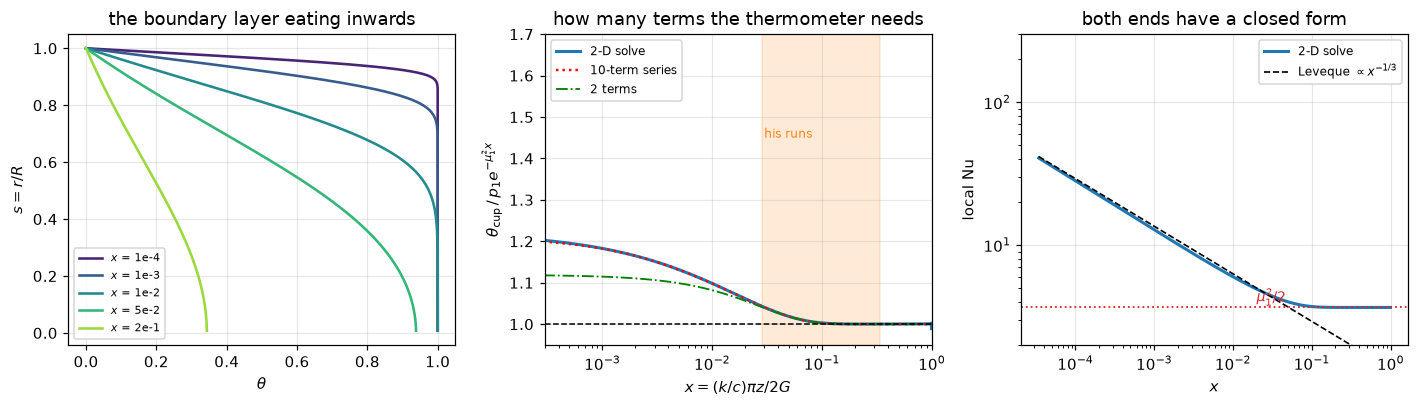

2-D solve, n_z = 600, n_r = 128, 6 Newton iterations
  mu_1 from the far-field decay   2.704379
  p_1  from the far-field decay   0.819396
  asymptotic Nu = mu_1^2/2        3.6568
  Graetz's printed mu_1           2.7043
  Graetz's fitted p_1             0.91264   <-- the constant he could not compute


In [6]:
MU1_2D, P1_2D = decay(SOL["x"], SOL["cup"])
x_nu, Nu = TUBE.nusselt(SOL["theta"])
C_LEVEQUE = 2.0 / (gamma(4.0 / 3.0) * 9.0 ** (1.0 / 3.0))

fig, axes = plt.subplots(1, 3, figsize=(13.0, 3.8))

xs_show = [1e-4, 1e-3, 1e-2, 0.05, 0.2]
for xt, col in zip(xs_show, plt.cm.viridis(np.linspace(0.1, 0.85, len(xs_show)))):
    j = np.argmin(abs(SOL["x"] - xt))
    axes[0].plot(np.r_[SOL["theta"][j], 0.0], np.r_[TUBE.s_c, 1.0], color=col,
                 lw=1.7, label=f"$x$ = {SOL['x'][j]:.0e}".replace("e-0", "e-"))
axes[0].set(xlabel=r"$\theta$", ylabel=r"$s = r/R$",
            title="the boundary layer eating inwards")
axes[0].legend(fontsize=7.5, loc="lower left")

one = P_CUP[0] * np.exp(-MU[0] ** 2 * SOL["x"])
ser = np.array([np.sum(P_CUP * np.exp(-MU ** 2 * xx)) for xx in SOL["x"]])
ser2 = np.array([np.sum(P_CUP[:2] * np.exp(-MU[:2] ** 2 * xx)) for xx in SOL["x"]])
axes[1].semilogx(SOL["x"], SOL["cup"] / one, color="tab:blue", lw=2.0, label="2-D solve")
axes[1].semilogx(SOL["x"], ser / one, "r:", lw=1.6, label="10-term series")
axes[1].semilogx(SOL["x"], ser2 / one, "g-.", lw=1.2, label="2 terms")
axes[1].axhline(1.0, color="k", ls="--", lw=1.0)
gm = ((obs.k_over_c_printed * np.pi * obs.tube_length_cm)
      / (2 * obs.mass_flow_g_min)).values
axes[1].axvspan(gm.min(), gm.max(), color="tab:orange", alpha=0.16)
axes[1].text(gm.min() * 1.05, 1.45, "his runs", fontsize=8, color="tab:orange")
axes[1].set(xlabel=r"$x = (k/c)\pi z/2G$", xlim=(3e-4, 1.0), ylim=(0.95, 1.7),
            ylabel=r"$\theta_{\rm cup}\,/\,p_1e^{-\mu_1^2x}$",
            title="how many terms the thermometer needs")
axes[1].legend(fontsize=8)

m = x_nu > 3e-5
axes[2].loglog(x_nu[m], Nu[m], color="tab:blue", lw=2.0, label="2-D solve")
axes[2].loglog(x_nu[m], C_LEVEQUE * (x_nu[m] / 2) ** (-1 / 3), "k--", lw=1.1,
               label=r"Leveque $\propto x^{-1/3}$")
axes[2].axhline(MU[0] ** 2 / 2, color="tab:red", lw=1.2, ls=":")
axes[2].text(2e-2, MU[0] ** 2 / 2 * 1.09, r"$\mu_1^2/2$", color="tab:red", fontsize=9)
axes[2].set(xlabel=r"$x$", ylabel=r"local $\mathrm{Nu}$", ylim=(2, 300),
            title="both ends have a closed form")
axes[2].legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f"2-D solve, n_z = {PUB['n_z']}, n_r = {PUB['n_r']}, {SOL['nit']} Newton iterations")
print(f"  mu_1 from the far-field decay   {MU1_2D:.6f}")
print(f"  p_1  from the far-field decay   {P1_2D:.6f}")
print(f"  asymptotic Nu = mu_1^2/2        {MU1_2D**2/2:.4f}")
print(f"  Graetz's printed mu_1           {C['graetz_root_mu1']}")
print(f"  Graetz's fitted p_1             {C['p1_working_formula']}   <-- the "
      "constant he could not compute")

## Validation

Seven checks and a defect-injection table. Two are against constants Graetz
prints, two against limits he never had, one is the arithmetic of his own
calibration re-run, one is the claim he makes about axial conduction, and one is
grid refinement on both axes and in the inlet region separately, followed by
§3b, which splits the agreement at the published grid into its two error
components.

In [7]:
# 1. His printed power series, against exact rational arithmetic.
#    V = sum a_k x^2k with a_k = sum_j c[k][j] mu^-2j; the recurrence follows from
#    the ODE. Setting x = mu collapses it to a polynomial in mu^2, which is what
#    he prints. Nothing here touches the pymrm solve.
exact_poly = series_coeffs()
printed_poly = [1.0, -C["series_coeff_mu2"], C["series_coeff_mu4"],
                -C["series_coeff_mu6"], C["series_coeff_mu8"],
                -C["series_coeff_mu10"]]


def poly_errors(exact):
    """Relative error of each printed coefficient against ``exact``."""
    return np.array([abs(printed_poly[k] / exact[k] - 1) if exact[k] else 0.0
                     for k in range(6)])


poly_err = poly_errors(exact_poly)
print("1. The polynomial Graetz prints for V(mu) = 0 (journal p. 87)")
print(f"   {'power':>7}{'printed':>18}{'exact (rationals)':>22}{'rel. error':>13}")
for k in range(6):
    flag = "   <-- wrong" if poly_err[k] > 1e-4 else ""
    print(f"   mu^{2*k:<4d}{printed_poly[k]:18.10g}{exact_poly[k]:22.10g}"
          f"{poly_err[k]:13.2e}{flag}")
N_EXACT_COEF = claims.count("series_coeffs_right_to_printed_digits", poly_err[1:], 1e-4,
                            above=False, min_margin=0.5,
                            note="printed coefficients mu^2..mu^10 within 1e-4 relative; "
                                 "relative distance of the nearest to 1e-4")
print(f"   {N_EXACT_COEF} of the 5 printed coefficients are exact to every digit he "
      "prints (the mu^0 term is 1),")
print("   which is a strong check on the page-image reading: the text layer gives 0.1575")
print("   for the 0.1875 above. The last two are arithmetic slips of his: "
      f"{(printed_poly[4] / exact_poly[4] - 1) * 100:+.2f} % and a")
print(f"   factor of {1/(printed_poly[5]/exact_poly[5]):.2f}.")
claims.value("series_coeff_mu8_printed_err", poly_err[4], rtol=1e-3)
claims.value("series_coeff_mu10_printed_err", poly_err[5], rtol=1e-3)

# The one glyph on the page that had to be argued rather than simply read. The
# factor-of-2.65 claim turns on it, so state what the alternative would give.
MU10_ALT = -9.4938e-9            # the same digits with the broken group read as 9
MU10_ALT_ERR = abs(MU10_ALT / exact_poly[5] - 1)
print("\n   ONE CAVEAT ON THE READING, because a headline number turns on it.")
print("   The third digit-group of the mu^10 coefficient is a BROKEN GLYPH on the")
print("   300 dpi bitmap. Magnified 16x it has an open left side, two left-hand")
print("   terminals and no closed upper bowl, so it is a 3 and the coefficient is")
print(f"   {printed_poly[5]:.4e}, which is the factor of "
      f"{1/(printed_poly[5]/exact_poly[5]):.2f} above. Had it been a 9:")
print(f"     read as 3 (taken here) {printed_poly[5]:12.4e}   "
      f"rel err {poly_err[5]:.3f}   <-- factor {1/(printed_poly[5]/exact_poly[5]):.2f}")
print(f"     read as 9 (rejected)   {MU10_ALT:12.4e}   "
      f"rel err {MU10_ALT_ERR:.3f}   <-- {MU10_ALT_ERR*100:.1f} %, an ordinary rounding slip")
print("   So the mu^8 slip stands whatever this glyph is, but the mu^10 FACTOR")
print("   rests on one damaged character read at 16x. The sidecar records it.")

1. The polynomial Graetz prints for V(mu) = 0 (journal p. 87)
     power           printed     exact (rationals)   rel. error
   mu^0                    1                     1     0.00e+00
   mu^2              -0.1875               -0.1875     0.00e+00
   mu^4             0.007921        0.007921006944     8.77e-07
   mu^6          -0.00014404      -0.0001440429687     2.06e-05
   mu^8           1.4592e-06       1.450798379e-06     5.79e-03   <-- wrong
   mu^10         -3.4938e-09       -9.26714482e-09     6.23e-01   <-- wrong
   3 of the 5 printed coefficients are exact to every digit he prints (the mu^0 term is 1),
   which is a strong check on the page-image reading: the text layer gives 0.1575
   for the 0.1875 above. The last two are arithmetic slips of his: +0.58 % and a
   factor of 2.65.

   ONE CAVEAT ON THE READING, because a headline number turns on it.
   The third digit-group of the mu^10 coefficient is a BROKEN GLYPH on the
   300 dpi bitmap. Magnified 16x it has an open

In [8]:
# 2. The eigenvalues. His mu_1 is excellent and his mu_2 is not, and the reason
#    is visible in his own polynomial.
def positive_roots(poly):
    """Positive real roots mu of a polynomial in mu^2 (coefficients low to high)."""
    r = np.sort(np.roots(poly[::-1]))
    return np.sqrt(r[(abs(r.imag) < 1e-9) & (r.real > 0)].real)


print("2. Eigenvalues")
roots_printed = positive_roots(printed_poly)
roots_exact_t = positive_roots(exact_poly)
mu1_err = abs(C["graetz_root_mu1"] / MU[0] - 1)
mu2_err = abs(C["graetz_root_mu2"] / MU[1] - 1)
print(f"   mu_1  printed {C['graetz_root_mu1']:<9.4f} exact {MU[0]:.6f}"
      f"   rel {mu1_err:.2e}")
print(f"   mu_2  printed {C['graetz_root_mu2']:<9.2f} exact {MU[1]:.6f}"
      f"   rel {mu2_err:.2e}   <-- {mu2_err*100:.1f} % low")
print(f"   his own 10th-order polynomial has positive roots at "
      f"{np.array2string(roots_printed, precision=4)},")
print(f"   and with the coefficients CORRECTED it has "
      f"{np.array2string(roots_exact_t, precision=4)}. So the series can place")
print("   mu_1 to four figures and cannot place mu_2 at all: the 6.50 he prints")
print("   comes from neither polynomial, and truncation, not arithmetic, is why.")
claims.value("mu1_printed_rel_err", mu1_err, rtol=0.01)
claims.value("mu2_printed_rel_err", mu2_err, rtol=1e-3)
print("\n   plug-flow zeros he prints (p. 83), against J_0:")
BESSEL_KEYS = ["bessel_zero_1", "bessel_zero_2", "bessel_zero_3", "bessel_zero_4"]


def bessel_errs(zeros):
    return np.array([abs(C[k] / zeros[i] - 1) for i, k in enumerate(BESSEL_KEYS)])


for i, key in enumerate(BESSEL_KEYS):
    print(f"     sigma_{i+1}  printed {C[key]:<12.6f} exact {SIGMA[i]:.6f}"
          f"   rel {abs(C[key]/SIGMA[i]-1):.2e}")
claims.value("bessel_zeros_printed_max_err", bessel_errs(SIGMA).max(), rtol=0.01)

2. Eigenvalues
   mu_1  printed 2.7043    exact 2.704364   rel 2.38e-05
   mu_2  printed 6.50      exact 6.679031   rel 2.68e-02   <-- 2.7 % low
   his own 10th-order polynomial has positive roots at [ 2.7046  5.9548 17.4641],
   and with the coefficients CORRECTED it has [2.7044]. So the series can place
   mu_1 to four figures and cannot place mu_2 at all: the 6.50 he prints
   comes from neither polynomial, and truncation, not arithmetic, is why.

   plug-flow zeros he prints (p. 83), against J_0:
     sigma_1  printed 2.404928     exact 2.404826   rel 4.26e-05
     sigma_2  printed 5.520240     exact 5.520078   rel 2.93e-05
     sigma_3  printed 8.653870     exact 8.653728   rel 1.64e-05
     sigma_4  printed 11.791560    exact 11.791534   rel 2.17e-06


In [9]:
# 3. The 2-D pymrm solve against the series route, refined on each axis
#    separately. These share NO code: one is a finite-volume solve of the PDE,
#    the other shoots the radial ODE and projects. They share only the physics.
#    Orders come from successive differences of three levels, so the other
#    axis's fixed error cancels and the exact value is not needed.
LADDERS = {"n_z": (dict(n_r=256), (75, 150, 300, 600, 1200)),
           "n_r": (dict(n_z=800), (16, 32, 64, 128))}


def ladder(tag, **kw):
    """mu_1 and p_1 along one ladder; ``kw`` are extra GraetzTube arguments."""
    fixed, sweep = LADDERS[tag]
    v = []
    for n in sweep:
        _, s_ = solve2d(**fixed, **kw, **{tag: n})
        v.append(decay(s_["x"], s_["cup"]))
    return np.array(sweep), np.array(v)


def orders(vals):
    """Observed orders from successive differences, one per three levels."""
    d = np.diff(vals)
    return np.log2(d[:-1] / d[1:])


print("3. 2-D solve vs the eigenfunction route, refining one axis at a time")
LAD = {}
for tag in LADDERS:
    fixed = LADDERS[tag][0]
    ns, v = ladder(tag)
    LAD[tag] = v
    om, op = orders(v[:, 0]), orders(v[:, 1])
    print(f"   refine {tag} ({', '.join(f'{k} = {w}' for k, w in fixed.items())}); "
          "order from the three levels ending at that row:")
    print(f"     {tag:>6}{'mu_1':>12}{'err':>11}{'order':>8}"
          f"{'p_1':>12}{'err':>11}{'order':>8}")
    for i, n in enumerate(ns):
        o = ("", "") if i < 2 else (f"{om[i-2]:8.2f}", f"{op[i-2]:8.2f}")
        print(f"     {n:6d}{v[i, 0]:12.6f}{v[i, 0]/MU[0]-1:+11.2e}{o[0]:>8}"
              f"{v[i, 1]:12.6f}{v[i, 1]/P_CUP[0]-1:+11.2e}{o[1]:>8}")
ORD_AX, ORD_RAD = orders(LAD["n_z"][:, 0]), orders(LAD["n_r"][:, 0])
LADDER_FLOOR = {t: np.abs(np.diff(LAD[t][:, 0])).min() / NEWTON_TOL for t in LAD}
print(f"   axial orders in mu_1 {np.array2string(ORD_AX, precision=2)}, radial "
      f"{np.array2string(ORD_RAD, precision=2)}: both axes second order, the axial")
print("   one approaching 2 from below as the limiter clips less. The smallest")
print("   difference on either ladder is more than 1e3 times the Newton tolerance.")
claims.bound("order_mu1_axial", ORD_AX[-1], min=1.8, max=2.1, basis="theory",
             note="successive differences, n_z 300/600/1200 at n_r 256")
claims.bound("order_mu1_axial_min", ORD_AX.min(), min=1.75, max=2.1, basis="theory",
             note="all triples from n_z = 75; pre-asymptotic below 2")
claims.bound("order_mu1_radial", ORD_RAD[-1], min=1.9, max=2.1, basis="theory",
             note="successive differences, n_r 32/64/128 at n_z 800")
claims.bound("order_mu1_radial_min", ORD_RAD.min(), min=1.9, max=2.1, basis="theory",
             note="all triples from n_r = 16")
claims.bound("ladder_axial_finest_diff_over_tol", LADDER_FLOOR["n_z"], min=1e3,
             basis="theory", note="smallest successive mu_1 difference over Newton tol")
claims.bound("ladder_radial_finest_diff_over_tol", LADDER_FLOOR["n_r"], min=1e3,
             basis="theory", note="smallest successive mu_1 difference over Newton tol")

# What first-order upwind would cost for the same axial error: its ladder is
# linear (one LU solve per rung), order 1, so it needs C/err cells.
_, UPW = ladder("n_z", limiter=None)
ORD_UPW = orders(UPW[:, 0])
print(f"\n   first-order upwind on the same ladder: orders "
      f"{np.array2string(ORD_UPW, precision=2)} (what it costs is in 3b, on the axial error alone).")

3. 2-D solve vs the eigenfunction route, refining one axis at a time


   refine n_z (n_r = 256); order from the three levels ending at that row:
        n_z        mu_1        err   order         p_1        err   order
         75    2.712921  +3.16e-03            0.839088  +2.45e-02        
        150    2.706697  +8.63e-04            0.824528  +6.69e-03        
        300    2.704943  +2.14e-04    1.83    0.820456  +1.72e-03    1.84
        600    2.704487  +4.54e-05    1.95    0.819411  +4.40e-04    1.96
       1200    2.704369  +1.57e-06    1.94    0.819138  +1.07e-04    1.94


   refine n_r (n_z = 800); order from the three levels ending at that row:
        n_r        mu_1        err   order         p_1        err   order
         16    2.695190  -3.39e-03            0.817902  -1.40e-03        
         32    2.702148  -8.20e-04            0.818925  -1.53e-04        
         64    2.703878  -1.80e-04    2.01    0.819175  +1.52e-04    2.03
        128    2.704310  -2.00e-05    2.00    0.819237  +2.28e-04    2.01
   axial orders in mu_1 [1.83 1.95 1.94], radial [2.01 2.  ]: both axes second order, the axial
   one approaching 2 from below as the limiter clips less. The smallest
   difference on either ladder is more than 1e3 times the Newton tolerance.



   first-order upwind on the same ladder: orders [0.9  0.97 0.97] (what it costs is in 3b, on the axial error alone).


**3b. What the published `mu1_rel_err_2d` is.**

The single agreement number at the published grid is not an accuracy: the axial
and radial errors carry opposite signs and largely cancel there. The two ladders
above measure each component without using the published grid. The axial ladder
runs at $n_r = 256$, so its Richardson limit in $n_z$ is the radial error at
$n_r = 256$; the radial ladder runs at $n_z = 800$, so its limit in $n_r$ is the
axial error at $n_z = 800$. Subtracting those gives the axial error of each
$n_z$ rung and the radial error of each $n_r$ rung. If the errors of the two axes
simply add, their sum must reproduce the error of grids that were not used to
build them, the published one among them. The cell below tests that.

In [10]:
def components(order_z, order_r):
    """Axial error per n_z rung and radial error per n_r rung (relative, signed)."""
    nz, rz = LADDERS["n_z"][1], LAD["n_z"][:, 0]
    nr, rr = LADDERS["n_r"][1], LAD["n_r"][:, 0]
    lim_z = rz[-1] + (rz[-1] - rz[-2]) / (2 ** order_z - 1)   # n_z -> inf, n_r = 256
    lim_r = rr[-1] + (rr[-1] - rr[-2]) / (2 ** order_r - 1)   # n_r -> inf, n_z = 800
    rad_256, ax_800 = lim_z / MU[0] - 1, lim_r / MU[0] - 1
    ax = {n: v / MU[0] - 1 - rad_256 for n, v in zip(nz, rz)}
    rad = {n: v / MU[0] - 1 - ax_800 for n, v in zip(nr, rr)}
    rad[256], ax[800] = rad_256, ax_800
    return ax, rad


AX, RAD = components(ORD_AX[-1], ORD_RAD[-1])
print("3b. The error at each grid, measured and as the sum of the two components")
print(f"    {'n_z':>6}{'n_r':>6}{'mu_1 rel err':>15}{'axial':>12}{'radial':>12}"
      f"{'sum':>12}")
SWEEP = {}
for nz, nr in ((600, 128), (600, 256), (1200, 128), (1200, 256)):
    _, s_ = solve2d(n_z=nz, n_r=nr)
    e = decay(s_["x"], s_["cup"])[0] / MU[0] - 1
    SWEEP[(nz, nr)] = e
    tag = "   <-- published" if (nz, nr) == (600, 128) else ""
    print(f"    {nz:6d}{nr:6d}{e:+15.2e}{AX[nz]:+12.2e}{RAD[nr]:+12.2e}"
          f"{AX[nz] + RAD[nr]:+12.2e}{tag}")


def separability_gap(ax, rad):
    """Largest |sum of components - measured| over the two grids not used to build them."""
    return max(abs(ax[nz] + rad[nr] - SWEEP[(nz, nr)]) for nz, nr in ((600, 128), (1200, 128)))


print(f"    (the radial ladder carries the axial error of n_z = 800, {AX[800]:+.1e}, in "
      "every rung; the axial ladder the radial error of n_r = 256, "
      f"{RAD[256]:+.1e})")
SEP_GAP = separability_gap(AX, RAD)
MU1_ERR_2D = abs(MU1_2D / MU[0] - 1)
print(f"    At the published grid the axial error is {AX[600]:+.1e} and the radial "
      f"{RAD[128]:+.1e};")
print(f"    they cancel to {SWEEP[(600, 128)]:+.1e}. On the two grids that built neither "
      "component the sum")
print(f"    reproduces the measured error to {SEP_GAP:.1e}. So the solver's accuracy at "
      f"the published grid")
print(f"    is that of its larger component, {max(abs(AX[600]), abs(RAD[128])):.1e} in "
      f"mu_1, and the {MU1_ERR_2D:.1e} reported as")
print("    `mu1_rel_err_2d` is a cancellation. Refining one axis alone removes part of")
print("    one component and the other shows: that is the 600/256 and 1200/128 rows.")
# What first-order upwind would cost for the same AXIAL error. Both ladders run at
# n_r = 256, so the radial error there is taken off both before comparing; upwind
# is order 1 (observed 0.90 to 0.97), so it needs about C/err cells, C from its
# finest rung. An order of 0.97 instead of 1 would move the factors by about 8 %.
def upwind_factor(n, vl_axial):
    c_upw = abs(UPW[-1, 0] / MU[0] - 1 - RAD[256]) * LADDERS["n_z"][1][-1]
    return c_upw / abs(vl_axial) / n


print("\n    cells first-order upwind needs for the van Leer axial error of a rung:")
UPW_FACTOR = {}
for n in LADDERS["n_z"][1][:3]:
    UPW_FACTOR[n] = upwind_factor(n, AX[n])
    print(f"      van Leer n_z = {n:5d} (axial error {AX[n]:+.2e}): about "
          f"{5 * round(UPW_FACTOR[n] / 5):.0f} times as many")
print("    The factor grows with the accuracy asked for, as orders 1 and 2 imply;")
print("    the order uncertainty of the upwind ladder leaves it good to about 10 %.")
claims.value("upwind_cells_factor_n75", UPW_FACTOR[75], note="axial errors only")
claims.value("upwind_cells_factor_n300", UPW_FACTOR[300], note="axial errors only")
claims.value("mu1_rel_err_2d", MU1_ERR_2D, note="a cancellation of the two components")
claims.value("mu1_err_axial_component_n600", AX[600])
claims.value("mu1_err_radial_component_n128", RAD[128])
claims.value("mu1_rel_err_600x256", abs(SWEEP[(600, 256)]))
claims.value("mu1_rel_err_1200x128", abs(SWEEP[(1200, 128)]))
claims.bound("mu1_components_separability_gap", SEP_GAP, max=2e-6, basis="chosen",
             note="components from the ladders reproduce two grids outside them; "
                  "below 1/20 of either component")

# The fit window. Fitting the EXACT series on the same x points measures what
# the window itself costs; the rest of any change is the solve's.
print("\n    the far-field fit window:")
print(f"      {'x_min':>8}{'exact series':>15}{'solve 600/128':>16}{'solve 1200/128':>16}")
ser_pub = np.array([np.sum(P_CUP * np.exp(-MU ** 2 * xx)) for xx in SOL["x"]])
_, s1200 = solve2d(n_z=1200, n_r=128)
FIT_BIAS = {}
for xm in (0.35, 0.5, 0.7):
    FIT_BIAS[xm] = decay(SOL["x"], ser_pub, xmin=xm)[0] / MU[0] - 1
    print(f"      {xm:8.2f}{FIT_BIAS[xm]:+15.1e}"
          f"{decay(SOL['x'], SOL['cup'], xmin=xm)[0]/MU[0]-1:+16.2e}"
          f"{decay(s1200['x'], s1200['cup'], xmin=xm)[0]/MU[0]-1:+16.2e}")
print("      The window costs below 1e-7 in mu_1 from x = 0.35 on. A later window moves")
print("      the solve's number because the axial cells grow downstream (x = X t^3), and")
print("      doubling n_z shrinks that change: it is discretisation error, not the fit.")
claims.bound("fit_window_bias_exact_series", abs(FIT_BIAS[0.35]), max=1e-7, basis="theory",
             note="decay() on the 10-term series at the published x points, x > 0.35")

# The area amplitude, which nothing else on this page checks.
P1_AREA_2D = decay(SOL["x"], SOL["area"])[1]
P1_AREA_ERR = abs(P1_AREA_2D / P_AREA[0] - 1)
P1_ERR_2D = abs(P1_2D / P_CUP[0] - 1)
print("\n    and the AREA mean, the amplitude the area-mean row in 8f rests on:")
print(f"      2-D solve, far field of theta_area   p_1,area = {P1_AREA_2D:.6f}")
print(f"      series projection with weight s ds   p_1,area = {P_AREA[0]:.6f}")
print(f"      agree to {P1_AREA_ERR:.1e}; p_1 (cup) agrees to {P1_ERR_2D:.1e}. The same "
      "two routes, no shared code.")
claims.value("p1_rel_err_2d", P1_ERR_2D)
claims.value("p1_area_rel_err_2d", P1_AREA_ERR)

3b. The error at each grid, measured and as the sum of the two components
       n_z   n_r   mu_1 rel err       axial      radial         sum
       600   128      +5.45e-06   +5.92e-05   -5.32e-05   +6.07e-06   <-- published
       600   256      +4.54e-05   +5.92e-05   -1.38e-05   +4.54e-05


      1200   128      -3.84e-05   +1.54e-05   -5.32e-05   -3.78e-05
      1200   256      +1.57e-06   +1.54e-05   -1.38e-05   +1.57e-06
    (the radial ladder carries the axial error of n_z = 800, +3.3e-05, in every rung; the axial ladder the radial error of n_r = 256, -1.4e-05)
    At the published grid the axial error is +5.9e-05 and the radial -5.3e-05;
    they cancel to +5.5e-06. On the two grids that built neither component the sum
    reproduces the measured error to 6.1e-07. So the solver's accuracy at the published grid
    is that of its larger component, 5.9e-05 in mu_1, and the 5.5e-06 reported as
    `mu1_rel_err_2d` is a cancellation. Refining one axis alone removes part of
    one component and the other shows: that is the 600/256 and 1200/128 rows.

    cells first-order upwind needs for the van Leer axial error of a rung:
      van Leer n_z =    75 (axial error +3.18e-03): about 15 times as many
      van Leer n_z =   150 (axial error +8.76e-04): about 25 times as many

In [11]:
# 4. The inlet. The eigenfunction series is useless here (it needs O(x^-1/2)
#    terms as x -> 0) but the boundary layer has its own similarity solution,
#    and its constant can be derived rather than quoted:
#       u ~ 4 u_bar y / R near the wall  =>  Nu -> 2/(Gamma(4/3) 9^(1/3)) x*^-1/3
LEV_GRID = dict(X=1e-3, z_grade=6.0, r_grade=6.0)
LEV_RUNGS = ((100, 40), (200, 80), (400, 160), (800, 320))


def leveque_c0(n_z=200, n_r=80, **kw):
    """Leveque constant read from the solve: Nu (x/2)^(1/3) extrapolated in x^(1/3)."""
    tube, s_ = solve2d(**{**LEV_GRID, "n_z": n_z, "n_r": n_r, **kw})
    xx, nn = tube.nusselt(s_["theta"])
    L = nn * (xx / 2) ** (1 / 3)
    i0, i1 = np.argmin(abs(xx - 1e-8)), np.argmin(abs(xx - 1e-7))
    c1 = (L[i1] - L[i0]) / (xx[i1] ** (1 / 3) - xx[i0] ** (1 / 3))
    return L[i0] - c1 * xx[i0] ** (1 / 3)


def leveque_ladder(rungs=LEV_RUNGS, **kw):
    return np.array([leveque_c0(a, b, **kw) for a, b in rungs])


print("4. The entrance region: local Nu against the Leveque limit")
print(f"   derived constant 2/(Gamma(4/3) 9^(1/3)) = {C_LEVEQUE:.6f}")
LEV = leveque_ladder()
LEV_ORDERS = orders(LEV)
LEV_ORDER = LEV_ORDERS[-1]
LEV_RICHS = LEV[1:] + np.diff(LEV) / 3.0       # Richardson limit of each pair, order 2
LEV_RICH = LEV_RICHS[-1]
print(f"     {'n_z':>6}{'n_r':>6}{'extrapolated C0':>18}{'rel err':>11}")
for (a, b), c0 in zip(LEV_RUNGS, LEV):
    print(f"     {a:6d}{b:6d}{c0:18.6f}{c0/C_LEVEQUE-1:+11.2e}")
LEVEQUE_ERR = abs(LEV[2] / C_LEVEQUE - 1)       # at 400 x 160
print(f"   observed orders from successive differences "
      f"{np.array2string(LEV_ORDERS, precision=2)}; the Richardson limits of the last")
print("   pairs lie " + ", ".join(f"{r/C_LEVEQUE-1:+.1e}" for r in LEV_RICHS[1:])
      + " from the constant. That remainder (the extrapolation in x^(1/3)")
print("   from x = 1e-8 and 1e-7, the sampled points, and the grid together) is not")
print("   converged on this ladder, and its cause is not separated here.")
print(f"\n   and the other end: asymptotic Nu = mu_1^2/2 = {MU[0]**2/2:.5f},")
print("   the value every heat-transfer text prints for a tube at constant")
print("   wall temperature.")
claims.value("leveque_const_rel_err", LEVEQUE_ERR)
claims.bound("leveque_order", LEV_ORDER, min=1.8, max=2.2, basis="theory",
             note="successive differences, rungs 200 to 800")
claims.bound("leveque_order_min", LEV_ORDERS.min(), min=1.8, max=2.2, basis="theory",
             note="successive differences, every triple")
claims.value("leveque_richardson_rel_err", abs(LEV_RICH / C_LEVEQUE - 1), rtol=0.1,
             note="Richardson on 400x160 and 800x320; the previous pair gives less")

4. The entrance region: local Nu against the Leveque limit
   derived constant 2/(Gamma(4/3) 9^(1/3)) = 1.076732


        n_z   n_r   extrapolated C0    rel err
        100    40          1.072256  -4.16e-03
        200    80          1.075592  -1.06e-03
        400   160          1.076423  -2.87e-04
        800   320          1.076624  -1.00e-04
   observed orders from successive differences [2.01 2.04]; the Richardson limits of the last
   pairs lie -3.0e-05, -3.8e-05 from the constant. That remainder (the extrapolation in x^(1/3)
   from x = 1e-8 and 1e-7, the sampled points, and the grid together) is not
   converged on this ladder, and its cause is not separated here.

   and the other end: asymptotic Nu = mu_1^2/2 = 3.65679,
   the value every heat-transfer text prints for a tube at constant
   wall temperature.


In [12]:
# 5. Graetz's own calibration, re-run. Three equations (his I), three unknowns.
#    This tests the transcription and his arithmetic. It CANNOT test the model:
#    zero degrees of freedom means it fits whatever it is given.
GMU = np.array([C["graetz_root_mu1"], C["graetz_root_mu2"]])
GP = np.array([C["p1_working_formula"], C["p2_working_formula"]])


def refit(mu2=None):
    m = np.array([GMU[0], GMU[1] if mu2 is None else mu2])

    def res(v):
        return [v[0] * np.exp(-v[2] * np.pi * l * m[0] ** 2 / (2 * G))
                + v[1] * np.exp(-v[2] * np.pi * l * m[1] ** 2 / (2 * G)) - t
                for t, l, G in zip(CAL.theta, CAL.tube_length_cm, CAL.mass_flow_g_min)]
    with warnings.catch_warnings():          # 8d feeds it a deliberate nonsense
        warnings.simplefilter("ignore")      # mu_2, which fsolve rightly dislikes
        return fsolve(res, [0.9, 0.012, 0.09])


p1f, p2f, kcf = refit()
LOGP1_ERR = abs(np.log10(p1f) + 10 - C["log_p1"])
P2_REFIT_ERR = abs(p2f / C["p2_working_formula"] - 1)
print("5. His calibration re-solved from the three starred rows")
print(f"   {'':10}{'p_1':>12}{'p_2':>12}{'k/c':>10}{'log p_1':>12}{'log p_2':>10}")
print(f"   {'refitted':10}{p1f:12.5f}{p2f:12.5f}{kcf:10.5f}"
      f"{np.log10(p1f)+10:12.5f}{np.log10(p2f)+10:10.5f}")
print(f"   {'printed':10}{C['p1_working_formula']:12.5f}"
      f"{C['p2_working_formula']:12.5f}{'':10}"
      f"{C['log_p1']:12.5f}{C['log_p2']:10.5f}")
print(f"   log p_1 recovered to {LOGP1_ERR:.1e} in the logarithm; p_2 to "
      f"{P2_REFIT_ERR*100:.1f} %, which is his own")
print("   iteration ('koennen nachher noch verbessert werden': can be improved")
print("   afterwards). The transcription and the reading of his formula are right.")
p1f2, p2f2, kcf2 = refit(mu2=MU[1])
print(f"   with the CORRECT mu_2 = {MU[1]:.4f} the same three rows give "
      f"p_1 = {p1f2:.5f}, p_2 = {p2f2:.5f}, k/c = {kcf2:.5f}")
P2_RATIO = P_CUP[1] / C["p2_working_formula"]
print(f"   his fitted p_2 is {P2_RATIO:.1f} times smaller than the computed "
      f"{P_CUP[1]:.6f}")
claims.value("calibration_logp1_abs_err", LOGP1_ERR, rtol=0.01)
claims.value("calibration_p2_rel_err", P2_REFIT_ERR, rtol=0.01)
claims.value("p2_computed_over_fitted", P2_RATIO, rtol=1e-3)

5. His calibration re-solved from the three starred rows
                      p_1         p_2       k/c     log p_1   log p_2
   refitted       0.91259     0.01259   0.09670     9.96028   8.10000
   printed        0.91264     0.01249               9.96030   8.09658
   log p_1 recovered to 2.3e-05 in the logarithm; p_2 to 0.8 %, which is his own
   iteration ('koennen nachher noch verbessert werden': can be improved
   afterwards). The transcription and the reading of his formula are right.
   with the CORRECT mu_2 = 6.6790 the same three rows give p_1 = 0.91309, p_2 = 0.01238, k/c = 0.09676
   his fitted p_2 is 7.8 times smaller than the computed 0.097527


In [13]:
# 6. The misprint on page 90, settled against his own 51 rows.
print("6. The exponent printed in his working formula for k (p. 90)")
print(f"   {'mu_1 used':>28}{'mean |dev| from his k/c column':>34}")


def formula_dev(m1):
    """Mean |k/c inverted with (m1, his mu_2, his p_i) / his k/c column - 1|."""
    kc = np.array([invert(t, l, G, np.array([m1, GMU[1]]), GP)
                   for t, l, G in zip(obs.theta, obs.tube_length_cm, obs.mass_flow_g_min)])
    return float(np.mean(np.abs(kc / obs.k_over_c_printed - 1)))


MISPRINT = {}
for lab, m1 in ((f"{C['graetz_root_mu1']} (his p. 87 root)", C["graetz_root_mu1"]),
                (f"{C['mu1_working_formula']} (as printed on p. 90)",
                 C["mu1_working_formula"]),
                (f"{C['brass_corrected_root']} (his p. 86 gamma_1)",
                 C["brass_corrected_root"])):
    MISPRINT[m1] = formula_dev(m1)
    print(f"   {lab:>28}{MISPRINT[m1]*100:32.2f} %")
FORMULA_DEV = MISPRINT[C["graetz_root_mu1"]]
# how far apart the two printings are, taken from the CSV's own page column
PGAP = PAGE_OF["mu1_working_formula"] - PAGE_OF["brass_corrected_root"]
print(f"   Decisive: {C['mu1_working_formula']} is a misprint for "
      f"{C['graetz_root_mu1']}. {C['brass_corrected_root']} is the")
print(f"   brass-wall-corrected Bessel root {PGAP} pages earlier "
      f"(journal p. {PAGE_OF['brass_corrected_root']}")
print(f"   against p. {PAGE_OF['mu1_working_formula']}), a plausible "
      "compositor's substitution, but the data,")
print("   not the guess, settle it.")
claims.value("formula_reproduces_kc_mean_dev", FORMULA_DEV, rtol=0.01)
claims.value("formula_misprint_kc_mean_dev", MISPRINT[C["mu1_working_formula"]], rtol=0.01)

6. The exponent printed in his working formula for k (p. 90)
                      mu_1 used    mean |dev| from his k/c column
        2.7043 (his p. 87 root)                            0.71 %
   2.4013 (as printed on p. 90)                           26.31 %
      2.401 (his p. 86 gamma_1)                           26.34 %
   Decisive: 2.4013 is a misprint for 2.7043. 2.401 is the
   brass-wall-corrected Bessel root 4 pages earlier (journal p. 86
   against p. 90), a plausible compositor's substitution, but the data,
   not the guess, settle it.


In [14]:
# 7. Axial conduction. He keeps it in the plug-flow equation, then argues it is
#    negligible: alpha*beta/a^2 + beta^2 = sigma^2/R^2, and dropping beta^2
#    "beeinflusst den Werth von beta_1 erst in der sechsten Stelle".
#    That is a claim with a number in it, so check it at his own conditions.
R_TUBE = C["tube_diameter_cm"] / 2.0


def axial_effect(row):
    """|beta_1(approx)/beta_1(exact) - 1| from his own quadratic, one run."""
    V_dot = row.mass_flow_g_min / row.density_g_cm3       # cm^3/min
    a2 = row.k_printed / row.density_g_cm3                # c ~ 1 for water
    alpha = V_dot / (np.pi * R_TUBE ** 2)                 # cm/min
    q = alpha / a2
    b_ex = (-q + np.sqrt(q ** 2 + 4 * SIGMA[0] ** 2 / R_TUBE ** 2)) / 2
    b_ap = a2 * SIGMA[0] ** 2 / (alpha * R_TUBE ** 2)
    return a2, alpha, 2 * alpha * R_TUBE / a2, b_ex, b_ap, abs(b_ap / b_ex - 1)


# The effect FALLS as the flow rises, so his claim has to be tested at his
# SLOWEST run, not a convenient fast one. Both ends are printed.
wat = obs[obs.liquid == "water"]
row_slow = wat.loc[wat.mass_flow_g_min.idxmin()]
row_fast = wat.loc[wat.mass_flow_g_min.idxmax()]
print("7. Axial conduction, at the two extremes of his water runs")
print(f"   {'':22}{'G, g/min':>10}{'head':>6}{'alpha, cm/min':>15}{'Pe':>9}"
      f"{'rel effect':>13}")
for lab, r_ in (("slowest (worst case)", row_slow), ("fastest", row_fast)):
    a2, alpha, pe, b_ex, b_ap, rel = axial_effect(r_)
    print(f"   {lab:22}{r_.mass_flow_g_min:10.4f}{r_.pressure_head:>6}"
          f"{alpha:15.0f}{pe:9.0f}{rel:13.2e}")
a2, alpha, PE_AX, beta_exact, beta_approx, AXIAL_REL = axial_effect(row_slow)
print(f"   At the slowest run: a^2 = {a2:.4f} cm2/min, "
      f"beta_1 exact {beta_exact:.9f} /cm,")
print(f"   neglecting beta^2 {beta_approx:.9f} /cm, relative effect "
      f"{AXIAL_REL:.2e}.")
print("   He says 'erst in der sechsten Stelle' (only in the sixth place); at his")
print(f"   WORST run it reaches the {int(np.ceil(-np.log10(AXIAL_REL)))}th "
      "significant figure, which is exactly what he")
print("   claims, and at his fastest it is a further order down. The metric below")
print("   is the worst case, not a convenient one.")
claims.value("axial_conduction_rel_effect", AXIAL_REL, rtol=0.01)

print("\n   And in the 2-D solve, where the term is 1/Pe^2 * d2theta/dx2. The")
print("   difference between two solves on the SAME grid isolates it: the")
print("   discretisation error common to both cancels to leading order.")
# first-order perturbation of the Poiseuille eigenvalue problem itself:
#   (1/s)(sV')' + lambda(1-s^2)V + (lambda^2/Pe^2)V = 0, lambda = mu^2
# gives  d(mu)/mu = -(mu^2/2Pe^2) * <V^2> / <(1-s^2)V^2>, both with weight s ds.
s1, V1, _ = V_profile(MU[0])


def c_pred(weight):
    """Predicted C in d(mu)/mu = C/Pe^2, projecting against ``weight(s) s ds``."""
    return -MU[0] ** 2 / 2 * (np.trapezoid(V1 ** 2 * s1, s1)
                              / np.trapezoid(weight(s1) * V1 ** 2 * s1, s1))


C_PRED = c_pred(lambda s: 1 - s ** 2)
PE_LIST = (20.0, 40.0, 80.0, 160.0)


C_XMAX = 0.8      # the Pe fits end before the outlet x = X = 1, where dtheta/dx = 0 is imposed


def c_observed(n_z, n_r, xmax=C_XMAX):
    """C = (mu_1(Pe)/mu_1(inf) - 1) Pe^2 per Pe, and its large-Pe Richardson limit.

    mu_1 is fitted on 0.35 < x < xmax; ``xmax=None`` fits to the outlet.
    """
    _, s0 = solve2d(n_z=n_z, n_r=n_r)
    base = decay(s0["x"], s0["cup"], xmax=xmax)[0]
    cs = []
    for pe in PE_LIST:
        _, s_ = solve2d(n_z=n_z, n_r=n_r, inv_pe2=1 / pe ** 2)
        cs.append((decay(s_["x"], s_["cup"], xmax=xmax)[0] / base - 1) * pe ** 2)
    cs = np.array(cs)
    return cs, cs[-1] + (cs[-1] - cs[-2]) / 3.0     # C(Pe) = C + b/Pe^2


print(f"     {'grid, fit window':>22}" + "".join(f"{f'Pe = {pe:g}':>11}" for pe in PE_LIST)
      + f"{'Pe -> inf':>11}{'vs predicted':>14}")
C_OBS = {}
for xmax in (C_XMAX, None):
    for nz, nr in ((300, 64), (600, 128)):
        cs, cinf = c_observed(nz, nr, xmax)
        C_OBS[(nz, nr, xmax)] = cinf
        win = f"x < {xmax:g}" if xmax else "to the outlet"
        print(f"     {f'{nz}x{nr}, {win}':>22}" + "".join(f"{c:11.4f}" for c in cs)
              + f"{cinf:11.4f}{(cinf / C_PRED - 1) * 100:+13.3f} %")
AXIAL_PERT_ERR = abs(C_OBS[(600, 128, C_XMAX)] / C_PRED - 1)
print(f"   Perturbing the eigenvalue problem analytically predicts C = -mu_1^2/2 * "
      f"<V^2>/<(1-s^2)V^2> = {C_PRED:.4f}.")
print("   C(Pe) still moves with Pe, so it is extrapolated in 1/Pe^2 from the two")
print(f"   largest Pe. Fitted on x < {C_XMAX:g} the limit agrees with the prediction "
      f"below 1e-3 (here {AXIAL_PERT_ERR:.1e}) on both grids.")
print("   Fitted to the outlet it does not: with 1/Pe^2 > 0 the outlet condition")
print("   dtheta/dx = 0 at x = X is a real boundary condition, and the last cells")
print("   before it carry its effect into the fit. That gap halves when the cells")
print("   halve, as an effect confined to the last cell or two does. The check shares no")
print("   code with the finite-volume solve.")
print(f"   At his Pe = {PE_AX:.0f} the shift is {abs(C_PRED)/PE_AX**2:.1e} in mu_1, far below")
print("   the discretisation error of any affordable grid, and the same verdict as")
print("   his own quadratic reaches for the plug-flow case.")
claims.bound("axial_pert_rel_gap", AXIAL_PERT_ERR, max=1e-3, basis="chosen",
             note="C extrapolated to large Pe on 600x128, fit on 0.35 < x < 0.8, against "
                  "the perturbation result; the residual is the grid's and the extrapolation's")
claims.value("axial_pert_C_predicted", C_PRED, rtol=1e-4)

# 7b. Is the flow laminar? He never says, and the model needs it. The three
#     printed pressure heights and the measured flows answer it with no external
#     constant at all: Poiseuille gives V proportional to head, turbulent pipe
#     flow roughly to head^0.5.
HEADS = {"I": C["head_upper_cm"], "II": C["head_middle_cm"], "III": C["head_lower_cm"]}


def flow_exponents(heads):
    out = []
    for liq, g in obs.groupby("liquid", sort=False):
        m_ = g.groupby("pressure_head").apply(
            lambda d: (d.mass_flow_g_min / d.density_g_cm3).mean(), include_groups=False)
        if len(m_) < 2:
            continue
        h = np.array([heads[k] for k in m_.index])
        out.append((liq, "/".join(m_.index), np.polyfit(np.log(h), np.log(m_.values), 1)[0]))
    return out


print("\n7b. The flow regime, from his printed pressure heights alone")
print(f"   {'liquid':12s}{'heads used':>12}{'exponent n in V ~ head^n':>28}")
EXPO = flow_exponents(HEADS)
for liq, hs, n_ in EXPO:
    print(f"   {liq:12s}{hs:>12}{n_:28.2f}")
EXPO_MEAN = float(np.mean([e[2] for e in EXPO]))
print(f"   mean exponent {EXPO_MEAN:.2f} (Poiseuille would give 1, fully")
print("   turbulent pipe flow about 0.5). The flow is laminar, so the Poiseuille")
print("   PROFILE is the right family, but this says nothing about whether it is")
print("   fully DEVELOPED over the tube, which is a separate question the paper")
print("   gives no way to answer: it would need the viscosity, which he does not")
print("   print, and the entrance length is what a developing profile turns on.")
claims.value("flow_vs_head_exponent_mean", EXPO_MEAN, rtol=0.01)

7. Axial conduction, at the two extremes of his water runs
                           G, g/min  head  alpha, cm/min       Pe   rel effect
   slowest (worst case)      8.6320   III           3053     1978     5.91e-06
   fastest                  36.4430     I          12889     7997     3.62e-07
   At the slowest run: a^2 = 0.0926 cm2/min, beta_1 exact 0.194900978 /cm,
   neglecting beta^2 0.194902130 /cm, relative effect 5.91e-06.
   He says 'erst in der sechsten Stelle' (only in the sixth place); at his
   WORST run it reaches the 6th significant figure, which is exactly what he
   claims, and at his fastest it is a further order down. The metric below
   is the worst case, not a convenient one.

   And in the 2-D solve, where the term is 1/Pe^2 * d2theta/dx2. The
   difference between two solves on the SAME grid isolates it: the
   discretisation error common to both cancels to leading order.
           grid, fit window    Pe = 20    Pe = 40    Pe = 80   Pe = 160  Pe -> inf  vs predi

            300x64, x < 0.8    -4.4024    -4.5304    -4.5640    -4.5725    -4.5754       -0.002 %


           600x128, x < 0.8    -4.4025    -4.5305    -4.5641    -4.5726    -4.5754       -0.001 %
      300x64, to the outlet    -4.4553    -4.5766    -4.6091    -4.6175    -4.6202       +0.978 %
     600x128, to the outlet    -4.4384    -4.5558    -4.5877    -4.5959    -4.5987       +0.507 %
   Perturbing the eigenvalue problem analytically predicts C = -mu_1^2/2 * <V^2>/<(1-s^2)V^2> = -4.5755.
   C(Pe) still moves with Pe, so it is extrapolated in 1/Pe^2 from the two
   largest Pe. Fitted on x < 0.8 the limit agrees with the prediction below 1e-3 (here 6.8e-06) on both grids.
   Fitted to the outlet it does not: with 1/Pe^2 > 0 the outlet condition
   dtheta/dx = 0 at x = X is a real boundary condition, and the last cells
   before it carry its effect into the fit. That gap halves when the cells
   halve, as an effect confined to the last cell or two does. The check shares no
   code with the finite-volume solve.
   At his Pe = 1978 the shift is 1.2e-06 in mu_1, far below
   the disc

### 8. Defect injection: what each published number moves for

Each row breaks one thing on purpose, re-runs the computation behind one or more
claims with the defect in place (a changed argument of the same function, never a
typed number), and hands the result to `claims.breaks`, which records whether the
claim's own check (its tolerance or its bound) catches it. Every claim must be
failed by at least one row, and the last cell raises otherwise. The table was
built for this physics; `A2.3`'s rows (mean subtraction, the 192/48 factor, slug
mass conservation) have no counterpart here.

In [15]:
print("8a. The 2-D solve at the published grid")
print(f"    {'injected defect':34s}{'mu_1':>10}{'rel err':>10}"
      f"{'p_1':>10}{'rel err':>10}{'p_1,area err':>13}")
BREAK_2D = {}
for kw in ({}, dict(nu_r=0), dict(plug=True), dict(limiter=None), dict(n_r=8)):
    lab = ", ".join(f"{k}={v}" for k, v in kw.items()) or "as published"
    _, s_ = solve2d(**{**PUB, **kw})
    mu_, p_ = decay(s_["x"], s_["cup"])
    pa_ = decay(s_["x"], s_["area"])[1]
    BREAK_2D[lab] = (mu_, p_, pa_)
    print(f"    {lab:34s}{mu_:10.5f}{abs(mu_/MU[0]-1):10.2e}"
          f"{p_:10.5f}{abs(p_/P_CUP[0]-1):10.2e}{abs(pa_/P_AREA[0]-1):13.2e}")
    if kw:
        brk(lab, "mu1_rel_err_2d", abs(mu_ / MU[0] - 1))
        brk(lab, "p1_rel_err_2d", abs(p_ / P_CUP[0] - 1))
        brk(lab, "p1_area_rel_err_2d", abs(pa_ / P_AREA[0] - 1))
_pl = BREAK_2D["plug=True"]
print("    Every row moves all three numbers far outside the published error. The plug")
print("    row is Graetz's own first model in his own variables, and it lands on")
print(f"    sigma_1 = {SIGMA[0]:.4f} and 4/sigma_1^2 = {P_PLUG[0]:.4f} "
      f"(here mu_1 {_pl[0]:.4f}, p_1 {_pl[1]:.4f}): the velocity")
print("    profile is what sets both.")

# the routes, the ladders and the components
_d6 = TUBE.solve_deferred(omega=0.6, tol=1e-6)
brk("deferred correction stopped at a change of 1e-6", "newton_vs_deferred_field",
    np.max(np.abs(_d6["theta"] - SOL["theta"])))
brk("omega=0.8 instead of 1", "deferred_omega1_change_after_120", period_two(TUBE, 0.8)[0])
brk("omega=0.9 instead of 1", "deferred_omega1_period2_ratio", period_two(TUBE, 0.9)[1])
_ou = ORD_UPW
brk("limiter=None in the ladder", "order_mu1_axial", _ou[-1])
brk("limiter=None in the ladder", "order_mu1_axial_min", _ou.min())
_, RG = ladder("n_r", r_grade=0.5)
brk("r_grade=0.5 (coarsest cells at the wall)", "order_mu1_radial", orders(RG[:, 0])[-1])
brk("r_grade=0.5 (coarsest cells at the wall)", "order_mu1_radial_min",
    orders(RG[:, 0]).min())
for t in ("n_z", "n_r"):
    name = {"n_z": "ladder_axial_finest_diff_over_tol",
            "n_r": "ladder_radial_finest_diff_over_tol"}[t]
    brk("guard evaluated for a Newton tol of 1e-6 (same differences)", name,
        np.abs(np.diff(LAD[t][:, 0])).min() / 1e-6)
_ax_up = {n: v / MU[0] - 1 - RAD[256] for n, v in zip(LADDERS["n_z"][1], UPW[:, 0])}
brk("van Leer axial errors replaced by upwind", "upwind_cells_factor_n75",
    upwind_factor(75, _ax_up[75]))
brk("van Leer axial errors replaced by upwind", "upwind_cells_factor_n300",
    upwind_factor(300, _ax_up[300]))
_ax1, _rad1 = components(1.0, 1.0)
brk("Richardson limits taken with order 1", "mu1_err_axial_component_n600", _ax1[600])
brk("Richardson limits taken with order 1", "mu1_err_radial_component_n128", _rad1[128])
brk("Richardson limits taken with order 1", "mu1_components_separability_gap",
    separability_gap(_ax1, _rad1))
for nz, nr, name in ((600, 256, "mu1_rel_err_600x256"), (1200, 128, "mu1_rel_err_1200x128")):
    _, s_ = solve2d(n_z=nz, n_r=nr, limiter=None)
    brk("limiter=None", name, abs(decay(s_["x"], s_["cup"])[0] / MU[0] - 1))
brk("fit window from x = 0.05", "fit_window_bias_exact_series",
    abs(decay(SOL["x"], ser_pub, xmin=0.05)[0] / MU[0] - 1))

# the series route
_mu_plug = eigen(n_modes=2, weight=lambda s: 1.0 + 0.0 * s)
brk("eigen(weight=1): plug flow", "nu_infinity", _mu_plug[0] ** 2 / 2)
brk("eigen(weight=1): plug flow", "mu1_printed_rel_err",
    abs(C["graetz_root_mu1"] / _mu_plug[0] - 1))
brk("eigen(weight=1): plug flow", "mu2_printed_rel_err",
    abs(C["graetz_root_mu2"] / _mu_plug[1] - 1))
brk("p_1 of the area mean", "p1_cup", P_AREA[0])
brk("p_2 of the area mean", "p2_cup", P_AREA[1])
brk("amplitudes(n=401)", "amplitude_quadrature_identity", amplitudes(MU[:3], n=401)[2].max())
brk("jn_zeros(1, ...): J_1 instead of J_0", "bessel_zeros_printed_max_err",
    bessel_errs(jn_zeros(1, 4)).max())

print("\n8b. The Leveque constant  (leveque_const_rel_err, leveque_order)")
print(f"    {'injected defect':34s}{'C0 at 400x160':>15}{'rel err':>11}")
for kw in ({}, dict(plug=True), dict(r_grade=1.0), dict(nu_r=0)):
    lab = ", ".join(f"{k}={v}" for k, v in kw.items()) or "as published"
    c0 = leveque_c0(400, 160, **kw)
    print(f"    {lab:34s}{c0:15.6f}{abs(c0/C_LEVEQUE-1):11.2e}")
    if kw:
        caught = brk(lab, "leveque_const_rel_err", abs(c0 / C_LEVEQUE - 1))
        if kw == dict(plug=True):
            _lp = leveque_ladder(LEV_RUNGS[:3], plug=True)
            brk(lab, "leveque_richardson_rel_err",
                abs((_lp[-1] + (_lp[-1] - _lp[-2]) / 3) / C_LEVEQUE - 1))
_lu = leveque_ladder(limiter=None)
brk("limiter=None", "leveque_order", orders(_lu)[-1])
brk("limiter=None", "leveque_order_min", orders(_lu).min())
print("    Leveque exists because u ~ 4*u_bar*y/R at the wall. Plug flow has none,")
print("    so the x^-1/3 law is the wrong law there and the extrapolated constant")
print("    is meaningless. A uniform radial mesh cannot resolve a layer that is")
print("    1e-3 of the radius thick.")
print("    THE nu_r ROW IS POWERLESS, AND FOR A REASON: at x = 1e-8 the thermal")
print("    layer is about 1e-3 R thick, so the wall is locally flat and the leading")
print("    entrance constant cannot see the curvature. This metric tests the wall")
print("    shear and the near-wall resolution; it does NOT test the geometry, and")
print("    8a is where the geometry is tested.")

8a. The 2-D solve at the published grid
    injected defect                         mu_1   rel err       p_1   rel err p_1,area err
    as published                         2.70438  5.45e-06   0.81940  4.21e-04     4.29e-04


    nu_r=0                               1.68161  3.78e-01   0.72907  1.10e-01     8.54e-02


    plug=True                            2.40486  1.11e-01   0.69189  1.55e-01     1.91e-01


    limiter=None                         2.68838  5.91e-03   0.79601  2.81e-02     2.81e-02
    n_r=8                                2.66684  1.39e-02   0.81353  6.74e-03     5.05e-03
    Every row moves all three numbers far outside the published error. The plug
    row is Graetz's own first model in his own variables, and it lands on
    sigma_1 = 2.4048 and 4/sigma_1^2 = 0.6917 (here mu_1 2.4049, p_1 0.6919): the velocity
    profile is what sets both.



8b. The Leveque constant  (leveque_const_rel_err, leveque_order)
    injected defect                     C0 at 400x160    rel err
    as published                             1.076423   2.87e-04


    plug=True                               24.622742   2.19e+01


    r_grade=1.0                              1.338878   2.43e-01


    nu_r=0                                   1.076420   2.90e-04


    Leveque exists because u ~ 4*u_bar*y/R at the wall. Plug flow has none,
    so the x^-1/3 law is the wrong law there and the extrapolated constant
    is meaningless. A uniform radial mesh cannot resolve a layer that is
    1e-3 of the radius thick.
    THE nu_r ROW IS POWERLESS, AND FOR A REASON: at x = 1e-8 the thermal
    layer is about 1e-3 R thick, so the wall is locally flat and the leading
    entrance constant cannot see the curvature. This metric tests the wall
    shear and the near-wall resolution; it does NOT test the geometry, and
    8a is where the geometry is tested.


In [16]:
print("8c. The series coefficients  (series_coeff_mu8_err, series_coeff_mu10_err)")
print("    These come from exact rational arithmetic, so a 'defect' has to be in")
print("    the recurrence. Dropping the -s^2 of the weight turns the equation")
print("    into Bessel's, and the polynomial must change:")
bp = series_coeffs(weight_term=False)
print(f"    {'power':>7}{'Graetz weight (1-s^2)':>24}{'weight dropped (Bessel)':>26}")
for k in range(4):
    print(f"    mu^{2*k:<4d}{exact_poly[k]:24.10g}{bp[k]:26.10g}")
print(f"    and the first root moves {MU[0]:.5f} -> {positive_roots(bp)[0]:.5f}, the "
      f"J_0 zero {SIGMA[0]:.5f}.")
_pe_b = poly_errors(bp)
brk("series_coeffs(weight_term=False)", "series_coeff_mu8_printed_err", _pe_b[4])
brk("series_coeffs(weight_term=False)", "series_coeff_mu10_printed_err", _pe_b[5])
brk("series_coeffs(weight_term=False)", "series_coeffs_right_to_printed_digits",
    int(np.sum(_pe_b[1:] < 1e-4)))

print("\n8d. His calibration refit  (calibration_logp1_abs_err)")
print(f"    {'injected defect':46s}{'p_1':>11}{'log p_1':>11}{'abs err':>11}")
for lab, m2 in ((f"as published (mu_2 = {GMU[1]:.2f}, his value)", GMU[1]),
                (f"mu_2 = {MU[1]:.4f} (the true second eigenvalue)", MU[1]),
                ("mu_2 = 3.00 (nonsense)", 3.0)):
    v = refit(mu2=m2)
    print(f"    {lab:46s}{v[0]:11.5f}{np.log10(v[0])+10:11.5f}"
          f"{abs(np.log10(v[0])+10-C['log_p1']):11.2e}")
brk("refit(mu2=true mu_2)", "calibration_logp1_abs_err",
    abs(np.log10(p1f2) + 10 - C["log_p1"]))
brk("refit(mu2=true mu_2)", "calibration_p2_rel_err", abs(p2f2 / C["p2_working_formula"] - 1))
brk("area-mean p_2 instead of the cup p_2", "p2_computed_over_fitted",
    P_AREA[1] / C["p2_working_formula"])
print("    The refit recovers his log p_1 only when it is given HIS mu_2. That is")
print("    the check working: it is a check on the transcription and on his")
print("    arithmetic, and it is NOT a check on the model; three constants")
print("    fitted to three rows fit anything. See 8f.")

print("\n8e. The misprint test  (formula_reproduces_kc)")
for m1, d_ in sorted(MISPRINT.items()):
    print(f"    mu_1 = {m1:<8} mean |dev| from his k/c column {d_*100:8.2f} %")
brk(f"mu_1 = {C['mu1_working_formula']} (the printed exponent)",
    "formula_reproduces_kc_mean_dev", MISPRINT[C["mu1_working_formula"]])
brk(f"mu_1 = {C['graetz_root_mu1']} (his p. 87 root)", "formula_misprint_kc_mean_dev",
    FORMULA_DEV)
brk("T_mean taken as T_in", "T_mean_rows_within_0p02", int((mean_T_check(obs.T_in_C) < 0.02).sum()))
brk("fastest water run instead of the slowest", "axial_conduction_rel_effect",
    axial_effect(row_fast)[-1])
brk("perturbation projected against s ds (area weight)", "axial_pert_C_predicted",
    c_pred(lambda s: 1.0 + 0.0 * s))
brk("perturbation projected against s ds (area weight)", "axial_pert_rel_gap",
    abs(C_OBS[(600, 128, C_XMAX)] / c_pred(lambda s: 1.0 + 0.0 * s) - 1))
brk("Pe fits extended to the outlet x = X", "axial_pert_rel_gap",
    abs(C_OBS[(600, 128, None)] / C_PRED - 1))
brk("heads I and III interchanged", "flow_vs_head_exponent_mean",
    np.mean([e[2] for e in flow_exponents({"I": HEADS["III"], "II": HEADS["II"],
                                           "III": HEADS["I"]})]))

8c. The series coefficients  (series_coeff_mu8_err, series_coeff_mu10_err)
    These come from exact rational arithmetic, so a 'defect' has to be in
    the recurrence. Dropping the -s^2 of the weight turns the equation
    into Bessel's, and the polynomial must change:
      power   Graetz weight (1-s^2)   weight dropped (Bessel)
    mu^0                          1                         1
    mu^2                    -0.1875                     -0.25
    mu^4             0.007921006944                  0.015625
    mu^6           -0.0001440429687          -0.0004340277778
    and the first root moves 2.70436 -> 2.40479, the J_0 zero 2.40483.

8d. His calibration refit  (calibration_logp1_abs_err)
    injected defect                                       p_1    log p_1    abs err
    as published (mu_2 = 6.50, his value)             0.91259    9.96028   2.28e-05
    mu_2 = 6.6790 (the true second eigenvalue)        0.91309    9.96051   2.15e-04
    mu_2 = 3.00 (nonsense)              

True

In [17]:
# 8f. THE STRUCTURAL ROW, and the point of the page.
print("8f. The spread of k/c across his three pressure heads")
print("    (the fitted row is STRUCTURAL: three constants fitted to three rows,")
print("     so it is zero to the fit tolerance and is deliberately NOT reported as a metric)")
print(f"    {'route':44s}{'head III':>10}{'head II':>10}{'head I':>10}{'spread':>9}")
order = CAL.mass_flow_g_min.values.argsort()


def cal_kc(mus, ps, half=2.0):
    """k/c of the three starred rows, lowest flow first, through (mus, ps)."""
    return [invert(CAL.theta[i], CAL.tube_length_cm[i], CAL.mass_flow_g_min[i],
                   mus, ps, half) for i in order]


def spread(v):
    return (max(v) - min(v)) / np.mean(v)


SPREAD, KC_ROUTE = {}, {}
routes = [("his fitted p_1, p_2 (nothing else known)", GMU, GP, 2.0),
          ("computed p_i, 1 term", MU[:1], P_CUP[:1], 2.0),
          ("computed p_i, 2 terms", MU[:2], P_CUP[:2], 2.0),
          ("computed p_i, 10 terms, nothing fitted", MU, P_CUP, 2.0),
          ("computed p_i, 10 terms, AREA mean", MU, P_AREA, 2.0),
          ("plug flow, his own p. 84 result", SIGMA, P_PLUG, 1.0)]
for lab, mus, ps, half in routes:
    v = cal_kc(mus, ps, half)
    SPREAD[lab], KC_ROUTE[lab] = spread(v), v
    print(f"    {lab:44s}{v[0]:10.5f}{v[1]:10.5f}{v[2]:10.5f}{SPREAD[lab]*100:8.2f}%")
EXACT_LAB = "computed p_i, 10 terms, nothing fitted"
SPREAD_EXACT = SPREAD[EXACT_LAB]
KC10 = KC_ROUTE[EXACT_LAB]
X_CAL = [KC10[j] * np.pi * CAL.tube_length_cm[i] / (2 * CAL.mass_flow_g_min[i])
         for j, i in enumerate(order)]
claims.value("kc_spread_calibration_unfitted", SPREAD_EXACT, rtol=0.01)
claims.value("kc_spread_area_mean", SPREAD["computed p_i, 10 terms, AREA mean"], rtol=0.01)
brk("his fitted constants", "kc_spread_calibration_unfitted", SPREAD[routes[0][0]])
brk("cup amplitudes instead of area", "kc_spread_area_mean", SPREAD_EXACT)

print("\n    Is it an artefact of truncating the series at 10 modes?")
MU_HI = eigen(n_modes=20, hi=70.0)
P_CUP_HI = amplitudes(MU_HI)[0]
v20 = cal_kc(MU_HI, P_CUP_HI)
KC20_GAP = max(abs(a / b - 1) for a, b in zip(v20, KC10))
print(f"      {'computed p_i, 20 terms':44s}{v20[0]:10.5f}{v20[1]:10.5f}"
      f"{v20[2]:10.5f}{spread(v20)*100:8.2f}%")
print(f"      The three k/c agree with the 10-term values below 1e-12 (here {KC20_GAP:.1e}). "
      "His three runs")
print(f"      sit at x = {', '.join(f'{xx:.3f}' for xx in X_CAL)}, where the 11th mode "
      f"is damped by")
print(f"      exp(-mu_11^2 x) <= {np.exp(-MU_HI[10]**2*min(X_CAL)):.0e} "
      f"(mu_11 = {MU_HI[10]:.2f}). Truncation is not the cause.")
claims.bound("kc_10_vs_20_modes", KC20_GAP, max=1e-12, basis="tolerance",
             note="the 11th mode is damped below 1e-16 at the calibration runs")
brk("2 modes instead of 10", "kc_10_vs_20_modes",
    max(abs(a / b - 1) for a, b in zip(cal_kc(MU[:2], P_CUP[:2]), v20)))

print("\n    Does it depend on the eigenfunction route at all? Invert the same")
print("    three rows through the 2-D SOLVE's own theta_cup(x) curve instead:")
print("    no eigenfunction anywhere, only the finite-volume field.")


def cal_kc_2d(sol):
    """k/c of the starred rows from theta_cup(x) of a 2-D solve alone."""
    logcup = CubicSpline(np.log(sol["x"]), np.log(sol["cup"]))
    out = []
    for i in order:
        th, l, G = CAL.theta[i], CAL.tube_length_cm[i], CAL.mass_flow_g_min[i]
        lx = brentq(lambda t: float(logcup(t)) - np.log(th), np.log(sol["x"][0]),
                    np.log(sol["x"][-1]), xtol=1e-15, rtol=1e-15)
        out.append(np.exp(lx) * 2.0 * G / (np.pi * l))
    return out


v2d = cal_kc_2d(SOL)
SPREAD_2D = spread(v2d)
print(f"      {'2-D theta_cup(x), no series at all':44s}{v2d[0]:10.5f}"
      f"{v2d[1]:10.5f}{v2d[2]:10.5f}{SPREAD_2D*100:8.2f}%")
print(f"      against the series route's {SPREAD_EXACT*100:.2f} %. The central claim "
      "of this page does")
print("      not depend on the eigenfunction calculation.")
claims.value("kc_spread_2d_route", SPREAD_2D, rtol=0.01)
brk("theta_cup(x) from the nu_r=0 solve", "kc_spread_2d_route",
    spread(cal_kc_2d(solve2d(**PUB, nu_r=0)[1])))


# how big is the thermometry error on that spread?
def amplify(th, l, G, mus=MU, ps=P_CUP, half=2.0):
    k0 = invert(th, l, G, mus, ps, half)
    k1 = invert(th * (1 + 1e-6), l, G, mus, ps, half)
    return abs((k1 / k0 - 1) / 1e-6)


div = C["thermometer_division_inlet_outlet"]        # E1, E2: 1/10 degree, p. 82
div_bath = C["thermometer_division_bath"]          # E3:     1/5  degree, p. 82


def sigma_spread(coarsen=1.0, e3=False, mass_pct=0.0, average=True):
    """sigma on the head-to-head spread of k/c, for one error model.

    theta = (U - T0)/(T1 - T0), so a half-division on E1 (T1) and E2 (U) enters
    as 0.5*div*sqrt(1 + theta^2)/(T1 - T0); the bath thermometer E3 enters as
    0.5*div_bath*|theta - 1|/(T1 - T0). `mass_pct` is a relative error on the
    weighed-and-timed mass flow, which passes straight through because
    x = (k/c) pi l / (2 G) holds theta fixed: dln(k/c) = dln G exactly.
    `average` divides the READING errors by sqrt(5): each starred row is the
    mean of five observations (p. 91). A weighing or timing bias does not
    average, so `mass_pct` never gets the sqrt(5).
    """
    sig = []
    for i in range(3):
        r_ = CAL.iloc[i]
        A_ = amplify(r_.theta, r_.tube_length_cm, r_.mass_flow_g_min)
        d2 = (0.5 * div * coarsen) ** 2 * (1.0 + r_.theta ** 2)
        if e3:
            d2 += (0.5 * div_bath * coarsen) ** 2 * (r_.theta - 1.0) ** 2
        dth = np.sqrt(d2) / (r_.T_in_C - r_.T_bath_C)
        s_ = A_ * dth / r_.theta
        if average:
            s_ = s_ / np.sqrt(5)
        sig.append(np.hypot(s_, mass_pct / 100.0) if mass_pct else s_)
    return float(np.hypot(max(sig), min(sig)))


SIG_SPREAD = sigma_spread()
print(f"\n    half a scale division ({div/2:.2f} K) on E1 and E2, five observations")
print(f"    per row, propagates to {SIG_SPREAD*100:.2f} % on that spread.")
print(f"    The 10-term spread is {SPREAD_EXACT*100:.1f} %, i.e. "
      f"{SPREAD_EXACT/SIG_SPREAD:.0f} sigma.")
print("    That is the NARROWEST defensible error budget: it carries E1 and E2")
print("    and nothing else. 8g widens it, names what it leaves out and gives the")
print("    range, because the honest headline is a range and not a single number.")
print("    The fitted route reads zero by construction and therefore proves")
print("    nothing; it is listed as the structural row it is.")

# 8g. The metrics that are not the 2-D solve.
print("\n8g. The error budget  (kc_spread_thermometry_sigma, ..._wide)")
print("    FIRST, what the narrow budget LEAVES OUT. It carries E1 and E2 only.")
print("    Two sources are missing, and adding either is legitimate:")
print(f"      {'error model':52s}{'sigma':>8}{'significance':>14}")
BUDGET = {}
for lab, kw in (
        ("E1,E2 half-division, 5 obs (narrow)", {}),
        (f"+ E3, the {div_bath} K bath thermometer (p. 82)", dict(e3=True)),
        ("+ E3 + 1 % on the weighed-and-timed mass", dict(e3=True, mass_pct=1.0)),
        ("+ E3, and no sqrt(5) averaging at all", dict(e3=True, average=False))):
    sg = sigma_spread(**kw)
    BUDGET[lab] = sg
    print(f"      {lab:52s}{sg*100:7.2f} %{SPREAD_EXACT/sg:11.1f} sigma")
SIG_SPREAD_WIDE = max(BUDGET.values())
print(f"    E3's {div_bath} K division is in this page's own constants file; the mass")
print("    flow, a weighing over a timed minute (p. 82), is a source of its own. So")
print(f"    the honest headline is a RANGE: {SPREAD_EXACT/SIG_SPREAD:.0f} sigma on his "
      f"stated thermometry down to {SPREAD_EXACT/SIG_SPREAD_WIDE:.0f} sigma")
print("    on the widest budget that can be built from what the paper says. The")
print("    conclusion survives all of them, and the narrow budget is the optimistic end.")
print("    NOTE WHAT THE ROWS BELOW CANNOT DO. They only make an ASSUMED source")
print("    coarser. No coarsening row can ADD a source, so a break table of this")
print("    shape cannot detect the understatement above, which is why the omissions")
print("    are named rather than tested.")
claims.value("kc_spread_thermometry_sigma", SIG_SPREAD, rtol=0.01)
claims.value("kc_spread_thermometry_sigma_wide", SIG_SPREAD_WIDE, rtol=0.01)
claims.value("kc_spread_significance", SPREAD_EXACT / SIG_SPREAD, rtol=0.01)
claims.value("kc_spread_significance_wide", SPREAD_EXACT / SIG_SPREAD_WIDE, rtol=0.01)

print("\n    SECOND, coarsening the assumed source, which is what a break row can do:")
for scale, avg, lab in (
        (1.0, True, "1/10 degree scale, 5 obs (narrow budget)"),
        (10.0, True, "1 degree scale, still 5 obs (10x coarser)"),
        (1.0, False, "1/10 degree scale, a single observation"),
        (10.0, False, "1 degree scale AND a single observation")):
    sg = sigma_spread(coarsen=scale, average=avg)
    print(f"      {lab:52s}{sg*100:7.2f} %{SPREAD_EXACT/sg:11.1f} sigma")
brk("sigma_spread(coarsen=10)", "kc_spread_thermometry_sigma", sigma_spread(coarsen=10.0))
brk("sigma_spread(coarsen=10)", "kc_spread_significance",
    SPREAD_EXACT / sigma_spread(coarsen=10.0))
_w10 = sigma_spread(coarsen=10.0, e3=True, average=False)
brk("widest budget with coarsen=10", "kc_spread_thermometry_sigma_wide", _w10)
brk("widest budget with coarsen=10", "kc_spread_significance_wide", SPREAD_EXACT / _w10)
print(f"    The 1-degree rows are a STRAWMAN, printed only to bound the table: p. 82")
print(f"    prints E1 and E2 as divided in 1/{int(round(1/div))} degree, and his own "
      "tables quote")
print("    temperatures to 0.01 K. On the last row the spread would sit at "
      f"{SPREAD_EXACT/sigma_spread(coarsen=10.0, average=False):.1f} sigma,")
print("    the threshold of insignificance; if that row were the truth the page would")
print("    have no result. It is not, and the reason is p. 82, not the arithmetic.")
print("    What actually carries the conclusion is not sigma at all:")
print("      (i)  the spread is MONOTONE in flow rate (8f, low flow -> high k/c),")
print("           which reading noise has no reason to be; and")
print("      (ii) it reproduces OUT OF SAMPLE on liquids and runs that were never")
print("           fitted: see 8h, which is the stronger of the two.")

print("\n    head_I_over_III_amplification: a property of the inversion, so it")
print("    changes with the constants inverted through:")


def head_ratio(mus, ps, half=2.0):
    a_ = []
    for h in ("I", "III"):
        g = obs[obs.pressure_head == h]
        a_.append(np.mean([amplify(r.theta, r.tube_length_cm, r.mass_flow_g_min, mus, ps,
                                   half) for _, r in g.iterrows()]))
    return a_[0] / a_[1]


HEAD_RATIO = {}
for lab, mus, ps, half in (("computed p_i, 10 terms", MU, P_CUP, 2.0),
                           ("his fitted two-term formula", GMU, GP, 2.0),
                           ("plug flow", SIGMA, P_PLUG, 1.0),
                           ("computed p_i, 1 term", MU[:1], P_CUP[:1], 2.0)):
    HEAD_RATIO[lab] = head_ratio(mus, ps, half)
    print(f"      {lab:40s} head I / head III = {HEAD_RATIO[lab]:5.2f}")
print("    The conclusion (head I is the worst-conditioned, not the best) is the")
print("    same whichever constants are used, which is why it survives the")
print("    disagreement the rest of this page is about.")

8f. The spread of k/c across his three pressure heads
    (the fitted row is STRUCTURAL: three constants fitted to three rows,
     so it is zero to the fit tolerance and is deliberately NOT reported as a metric)
    route                                         head III   head II    head I   spread
    his fitted p_1, p_2 (nothing else known)       0.09671   0.09671   0.09671    0.00%
    computed p_i, 1 term                           0.08198   0.05853   0.04554   58.76%
    computed p_i, 2 terms                          0.08270   0.07212   0.06950   17.65%
    computed p_i, 10 terms, nothing fitted         0.08270   0.07262   0.07094   15.58%
    computed p_i, 10 terms, AREA mean              0.04192   0.01726   0.01322  118.94%
    plug flow, his own p. 84 result                0.03961   0.02708   0.02448   49.77%

    Is it an artefact of truncating the series at 10 modes?


      computed p_i, 20 terms                         0.08270   0.07262   0.07094   15.58%
      The three k/c agree with the 10-term values below 1e-12 (here 2.4e-15). His three runs
      sit at x = 0.083, 0.029, 0.021, where the 11th mode is damped by
      exp(-mu_11^2 x) <= 1e-17 (mu_11 = 42.67). Truncation is not the cause.

    Does it depend on the eigenfunction route at all? Invert the same
    three rows through the 2-D SOLVE's own theta_cup(x) curve instead:
    no eigenfunction anywhere, only the finite-volume field.
      2-D theta_cup(x), no series at all             0.08270   0.07263   0.07095   15.58%
      against the series route's 15.58 %. The central claim of this page does
      not depend on the eigenfunction calculation.

    half a scale division (0.05 K) on E1 and E2, five observations
    per row, propagates to 0.77 % on that spread.
    The 10-term spread is 15.6 %, i.e. 20 sigma.
    That is the NARROWEST defensible error budget: it carries E1 and E2
    and 

### 8h. The out-of-sample test, the one Graetz sets himself

Everything above is derived on the **three starred rows**, which are also the
three rows his $p_1$, $p_2$ and $k/c$ were fitted to. That is the weakest place
to make the argument, and it is not necessary: he states the test himself, twice.
On page 89 he asks whether it matters *"ob man nun die oberste, mittelste oder
unterste Druckhöhe benutzte"* (whether one uses the upper, middle or lower
pressure head), and on page 90 he asserts it does not.

So run it. For each liquid measured at more than one head, invert every run and
compare the head-to-head means, with his fitted constants and with the computed
ones. **Apart from the three starred rows, none of the runs was fitted to
anything** (the cell prints the count).

In [18]:
print("8h. His own consistency test, run on every liquid he measured at more")
print("    than one pressure head. Spread = (max - min)/mean of the per-head mean")
print(f"    k/c. The three starred rows are 3 of the {len(obs)}; everything else is out of")
print("    sample.")
print(f"    {'liquid':12s}{'runs':>6}{'heads':>12}"
      f"{'spread, his fitted p_i':>24}{'spread, computed p_i':>22}")


def head_means(g, mus, ps):
    """Mean k/c per pressure head of one liquid, inverted through (mus, ps)."""
    kc = np.array([invert(r.theta, r.tube_length_cm, r.mass_flow_g_min, mus, ps)
                   for _, r in g.iterrows()])
    return pd.Series(kc, index=g.pressure_head.values).groupby(level=0).mean()


def oos_spread(g, mus, ps):
    m_ = head_means(g, mus, ps)
    return (m_.max() - m_.min()) / m_.mean()


def lowest_head_lead(mus, ps):
    """Per multi-head liquid: k/c at its lowest head over the largest other head mean, - 1."""
    out = []
    for _, g in obs.groupby("liquid", sort=False):
        m_ = head_means(g, mus, ps)
        if len(m_) < 2:
            continue
        low = max(m_.index, key=lambda h: len(h))      # heads I > II > III in height
        out.append(m_[low] / m_.drop(low).max() - 1)
    return np.array(out)


OOS = {}
for liq, g in obs.groupby("liquid", sort=False):
    heads = "/".join(sorted(g.pressure_head.unique()))
    if g.pressure_head.nunique() < 2:
        print(f"    {liq:12s}{len(g):6d}{heads:>12}"
              f"{'-- one head only, cannot test --':>46}")
        continue
    OOS[liq] = (oos_spread(g, GMU, GP), oos_spread(g, MU, P_CUP))
    print(f"    {liq:12s}{len(g):6d}{heads:>12}"
          f"{OOS[liq][0]*100:23.1f} %{OOS[liq][1]*100:21.1f} %")
N_UNFITTED = len(obs) - len(CAL)
print(f"\n    With his fitted constants the test passes, as he says it does: "
      f"{max(v[0] for v in OOS.values())*100:.1f} % at")
print("    worst. With the computed constants it fails on every liquid that has "
      "three")
print(f"    heads: water {OOS['water'][1]*100:.1f} %, alcohol "
      f"{OOS['alcohol'][1]*100:.1f} %, and all {len(obs[obs.liquid=='cuso4'])} "
      f"copper-sulfate rows")
print(f"    {OOS['cuso4'][1]*100:.1f} %, against {OOS['water'][0]*100:.1f} %, "
      f"{OOS['alcohol'][0]*100:.1f} % and {OOS['cuso4'][0]*100:.1f} % with his. "
      "The two-head")
print("    liquids span a much smaller flow range and separate the two routes much")
print("    less, which is itself the right direction.")
LEAD = lowest_head_lead(MU, P_CUP)
N_LEAD = claims.count("liquids_lowest_head_highest_kc", LEAD, 0.0, min_margin=1e-3,
                      relative=False, note="k/c at the lowest head over the next highest, "
                      "minus 1, per multi-head liquid; computed constants")
print(f"\n    And the direction is the same every time: in {N_LEAD} of the {len(LEAD)} "
      "liquids measured at")
print("    more than one head the lowest head gives the highest k/c (with his fitted")
print(f"    constants in {int(np.sum(lowest_head_lead(GMU, GP) > 0))}). Reading noise has "
      "no reason to do that on every liquid at")
print(f"    once, and this is not the fitted rows: {N_UNFITTED} of the "
      f"{len(obs)} were never fitted.")
brk("his fitted constants", "liquids_lowest_head_highest_kc",
    int(np.sum(lowest_head_lead(GMU, GP) > 0)))
print("    This is the strongest evidence on the page that the 8f disagreement is")
print("    real, and it is stronger than any sigma in 8g, because it needs no error")
print("    model at all.")
for liq in ("water", "cuso4", "alcohol"):
    claims.value(f"kc_spread_out_of_sample_{liq}", OOS[liq][1], rtol=0.01)
    claims.value(f"kc_spread_out_of_sample_{liq}_fitted", OOS[liq][0], rtol=0.01)
    brk("his fitted constants", f"kc_spread_out_of_sample_{liq}", OOS[liq][0])
    brk("computed constants", f"kc_spread_out_of_sample_{liq}_fitted", OOS[liq][1])
claims.exact("runs_never_fitted", N_UNFITTED, structural=True,
             note="rows of the CSV minus the starred calibration rows")

8h. His own consistency test, run on every liquid he measured at more
    than one pressure head. Spread = (max - min)/mean of the per-head mean
    k/c. The three starred rows are 3 of the 51; everything else is out of
    sample.
    liquid        runs       heads  spread, his fitted p_i  spread, computed p_i
    water           13    I/II/III                    3.6 %                 17.0 %
    cuso4           11    I/II/III                    4.8 %                 20.9 %
    alcohol          7    I/II/III                    7.2 %                 17.8 %
    nacl             7        I/II                    2.9 %                  1.2 %
    znso4            8           I              -- one head only, cannot test --
    turpentine       5        I/II                    0.2 %                  5.0 %

    With his fitted constants the test passes, as he says it does: 7.2 % at
    worst. With the computed constants it fails on every liquid that has three
    heads: water 17.0 %, alcohol 17

## What pymrm adds

Three things, and the third is not flattering to the exercise.

**1. The constants.** Graetz's $p_i$ are pure numbers: they do not depend on
$R$ at all, contrary to the sentence quoted above, because $R$ scales out of the
eigenvalue problem. All ten are computed by the eigenfunction projection. The
2-D finite-volume solve on the pymrm operators, which never forms an
eigenfunction, confirms $p_1$ (cup and area mean) from its far-field decay,
and the summed series where it matters: inverting the calibration runs through
the solve's own $\theta_{\text{cup}}(x)$ gives the same spread (§8f). It does
not give $p_2$ to $p_{10}$ on its own.

**2. Two limits he did not have.** The entrance region and the far field both
have closed forms that the eigenfunction series cannot supply: the first
because it would need infinitely many terms, the second because it *is* the
first term, which he could see but not name. The asymptotic Nusselt number that
every heat-transfer text prints is $\mu_1^2/2$.

**3. What happens when his fitted constants are replaced by the computed ones.**
His calibration fits three constants to three runs, so its perfect agreement is
guaranteed and is not evidence. Substituting the computed amplitudes removes the
fit, and the three runs then no longer agree on a single $k/c$. The
disagreement is monotone in flow rate, far outside his thermometry on any error
budget that can be built from the paper (§8g gives the range, and says what the
budget excludes), and, the part that needs no error budget at all, it
**reproduces on the runs that were never fitted** (§8h). That last test is
Graetz's own, proposed on his page 89.

So the honest verdict runs the other way from the framing: **Graetz's empirical
calibration was doing real work, and it was not merely standing in for a
calculation he could not do.** It was absorbing a systematic error in the
apparatus that his own method could not see, and removing it makes his numbers
worse, not better.

On the pymrm side the page is a plain use of the library: a steady 2-D
convection-diffusion problem on `construct_grad`, `construct_div` and
`construct_convflux_upwind`, van Leer face values with their exact Jacobian from
`ConvFluxTVD`, `newton`, and the wall gradient from `compute_boundary_values`.
None of it is new numerics; the operators make the second, independent route to
$\mu_1$, $p_1$ and the summed series cheap to build and to refine on each axis.

### What this page cannot conclude

It does not identify the systematic effect. The spread is real, monotone in
flow rate and many times the propagated reading error, but *which* effect it
is stays open, and three candidates are worth writing down so the next reader
does not have to re-derive them:

- **A velocity profile that is not fully developed.** His printed heads and
  measured flows put $\dot V$ all but exactly proportional to head (§7b), so the
  flow is laminar and Poiseuille is the right family. Whether it is *developed*
  over the tube depends on the entrance length, which needs a viscosity the paper
  does not print, and settling it needs a momentum solve this page does not do.
  Note the direction: the other extreme, plug flow, moves the inferred $k/c$
  further *down*, not up (the plug row of §8f), so a flatter profile does not on
  its own close the gap.
- **Heat exchanged outside the cooled length**, in the corks, or in the glass
  tubes carrying the thermometers. Any flow-independent loss weighs more at low
  flow, which is the right direction, but the paper gives no dimensions for it.
- **The area-versus-cup mean.** Graetz's page-88 formula integrates over the
  cross-section; a collected sample is flow-weighted. §8f shows the two differ
  enormously, but the area mean makes the spread *worse*, so this is not the
  explanation either.

And the page does not claim Graetz's conductivities are wrong. It claims the
route by which he obtained them cannot be checked from inside the paper, that
checking it from outside makes it fail, and that his numbers survive because two
fitted constants absorbed the failure.

In [19]:
print("What replacing the two fitted constants does to his conductivities")
print("(k/c inverted run by run; k = c * k/c; his own reference values from p. 80")
print(" and p. 93 for scale, all in g-cal/(cm min K))")


def k_shifts(mus, ps):
    """Per liquid: (name, runs, his mean k, mean k inverted through (mus, ps), change)."""
    out = []
    for liq, g in obs.groupby("liquid", sort=False):
        ci = (g.k_printed / g.k_over_c_printed).mean()
        kc = np.array([invert(r.theta, r.tube_length_cm, r.mass_flow_g_min, mus, ps)
                       for _, r in g.iterrows()])
        out.append((liq, len(g), g.k_printed.mean(), (kc * ci).mean(),
                    (kc * ci).mean() / g.k_printed.mean() - 1))
    return out


summary = k_shifts(MU, P_CUP)
print(f"   {'liquid':12s}{'n':>3}{'his k':>10}{'k, unfitted':>13}{'change':>10}")
for liq, n, kh, ke, ch in summary:
    print(f"   {liq:12s}{n:3d}{kh:10.4f}{ke:13.4f}{ch*100:9.1f} %")
WATER = [s for s in summary if s[0] == "water"][0]
WATER_SHIFT = WATER[4]
print("\n   his own reference points for water, all printed in the paper:")
print(f"     Weber   (4 C)  {C['k_water_weber_4C']}      "
      f"Weber   (23 C) {C['k_water_weber_23C']}")
print(f"     Lorberg (23 C) {C['k_water_lorberg_23C']}     "
      f"Graetz  (30 C) {C['k_water_graetz_30C']}")
print(f"     Weber via Lorberg's temperature coefficient, carried to 30 C: "
      f"{C['k_water_lorberg_carried_30C']:.4f}")
print("   He notes that carried value, "
      "'was mit dem von mir bestimmten Werth gut uebereinstimmt'")
print(f"   ({abs(C['k_water_lorberg_carried_30C']/C['k_water_graetz_30C']-1)*100:.1f} % "
      f"from his own {C['k_water_graetz_30C']}). The unfitted inversion gives "
      f"{WATER[3]:.4f},")
print(f"   {abs(WATER_SHIFT)*100:.0f} % below both, and the agreement he had is gone.")
_ch = [s[4] for s in summary]
claims.value("water_k_shift_unfitted", WATER_SHIFT, rtol=0.01)
claims.value("k_drop_unfitted_least", -max(_ch), rtol=0.01,
             note="smallest fall of a liquid's mean k without the fit")
claims.value("k_drop_unfitted_most", -min(_ch), rtol=0.01,
             note="largest fall of a liquid's mean k without the fit")
_chf = [s[4] for s in k_shifts(GMU, GP)]
brk("his fitted constants", "water_k_shift_unfitted",
    [s[4] for s in k_shifts(GMU, GP) if s[0] == "water"][0])
brk("his fitted constants", "k_drop_unfitted_least", -max(_chf))
brk("his fitted constants", "k_drop_unfitted_most", -min(_chf))

What replacing the two fitted constants does to his conductivities
(k/c inverted run by run; k = c * k/c; his own reference values from p. 80
 and p. 93 for scale, all in g-cal/(cm min K))
   liquid        n     his k  k, unfitted    change
   water        13    0.0945       0.0741    -21.6 %
   cuso4        11    0.0922       0.0707    -23.3 %
   alcohol       7    0.0433       0.0361    -16.6 %
   nacl          7    0.0964       0.0736    -23.6 %
   znso4         8    0.0920       0.0695    -24.5 %
   turpentine    5    0.0307       0.0247    -19.4 %

   his own reference points for water, all printed in the paper:
     Weber   (4 C)  0.0745      Weber   (23 C) 0.0857
     Lorberg (23 C) 0.09108     Graetz  (30 C) 0.0945
     Weber via Lorberg's temperature coefficient, carried to 30 C: 0.0940
   He notes that carried value, 'was mit dem von mir bestimmten Werth gut uebereinstimmt'
   (0.5 % from his own 0.0945). The unfitted inversion gives 0.0741,
   22 % below both, and the agreem

True

In [20]:
# The other thing the inversion settles: which of his three pressure heads is
# the good one. He states a preference, on p. 90, and it is the wrong way round.
print("Which pressure head gives the best-conditioned measurement?")
print("Graetz, p. 90: 'Die Beobachtungen bei der groessten Druckhoehe sind den")
print("anderen ueberlegen, weil die Ausflusstemperatur U sich bei diesen der")
print("Einflusstemperatur T_1 am meisten naehert.'  (The observations at the")
print("greatest pressure head are superior to the others, because the outflow")
print("temperature U there comes closest to the inflow temperature T_1.)")
print(f"\n   {'head':>5}{'runs':>6}{'theta':>9}{'T_1 - U':>10}"
      f"{'|dln(k/c)/dln(theta)|':>23}{'sigma(k/c)':>12}")
AMP = {}
for h, g in obs.groupby("pressure_head"):
    a_ = np.mean([amplify(r.theta, r.tube_length_cm, r.mass_flow_g_min)
                  for _, r in g.iterrows()])
    dth = 0.5 * div * np.hypot(1.0, g.theta) / (g.T_in_C - g.T_bath_C)
    AMP[h] = a_
    print(f"   {h:>5}{len(g):6d}{g.theta.mean():9.4f}"
          f"{(g.T_in_C-g.T_out_C).mean():10.2f}{a_:23.2f}"
          f"{np.mean(a_*dth/g.theta)*100:11.1f} %")
_dT = {h: (obs[obs.pressure_head == h].T_in_C - obs[obs.pressure_head == h].T_out_C).mean()
       for h in ("I", "III")}
print("\n   His reason is sound as far as it goes: at head I the liquid changes")
print(f"   temperature by {_dT['I']:.1f} K rather than {_dT['III']:.1f} K, so the T at "
      "which k is quoted is")
print("   better defined, and he is explicitly worried about the temperature")
print(f"   coefficient. But the inversion amplifies a temperature error by "
      f"{AMP['I']/AMP['III']:.1f}x")
print("   more at head I than at head III, and he does not weigh the two. The")
print("   trade-off is only visible once the inversion is done properly, which")
print("   needs the amplitudes he did not have.")
claims.value("head_I_over_III_amplification", AMP["I"] / AMP["III"], rtol=0.01)
brk("plug-flow constants in the inversion", "head_I_over_III_amplification",
    HEAD_RATIO["plug flow"])

Which pressure head gives the best-conditioned measurement?
Graetz, p. 90: 'Die Beobachtungen bei der groessten Druckhoehe sind den
anderen ueberlegen, weil die Ausflusstemperatur U sich bei diesen der
Einflusstemperatur T_1 am meisten naehert.'  (The observations at the
greatest pressure head are superior to the others, because the outflow
temperature U there comes closest to the inflow temperature T_1.)

    head  runs    theta   T_1 - U  |dln(k/c)/dln(theta)|  sigma(k/c)
       I    32   0.6559      8.30                   3.45        1.4 %
      II    15   0.6063     10.56                   2.89        1.1 %
     III     4   0.3077     22.54                   1.11        0.9 %

   His reason is sound as far as it goes: at head I the liquid changes
   temperature by 8.3 K rather than 22.5 K, so the T at which k is quoted is
   better defined, and he is explicitly worried about the temperature
   coefficient. But the inversion amplifies a temperature error by 3.1x
   more at head I th

True

In [21]:
# The break table, as recorded by claims.breaks.
print(f"{'injected defect':<50} {'claim':<40} {'clean':>12} {'broken':>12}  caught")
for name, metric, clean, broken, caught in BREAK:
    is_bound = claims.metrics[metric]["kind"] == "bound"
    shown = f"(here {clean:.1e})" if is_bound else f"{clean:12.4g}"
    broke = f"(here {broken:.0e})" if abs(broken) < 1e-10 else f"{broken:12.4g}"
    print(f"{name[:50]:<50} {metric[:40]:<40} {shown:>12} {broke:>12}  "
          f"{'yes' if caught else 'NO'}")
_caught = {m for _, m, _, _, c in BREAK if c}
_structural = sorted(k for k, c in claims.metrics.items() if c.get("structural"))
_open = sorted(k for k in claims.metrics if k not in _caught and k not in _structural)
print(f"\n{len(BREAK)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at "
      f"least one row; structural: {', '.join(_structural) or 'none'}; "
      f"open: {', '.join(_open) or 'none'}")
_uncaught = [(n, m) for n, m, _, _, c in BREAK if not c]
print("rows that do not fail their claim: "
      + (", ".join(f"{n} -> {m}" for n, m in _uncaught) or "none"))
_nits = [r["nit"] for t, r in _SOLVES.values() if t.tvd is not None]
print(f"\nNewton iterations over the {len(_nits)} van Leer solves on this page: "
      f"{min(_nits)} to {max(_nits)}, every one converged")

injected defect                                    claim                                           clean       broken  caught
nu_r=0                                             mu1_rel_err_2d                              5.454e-06       0.3782  yes
nu_r=0                                             p1_rel_err_2d                               0.0004213       0.1099  yes
nu_r=0                                             p1_area_rel_err_2d                          0.0004295      0.08543  yes
plug=True                                          mu1_rel_err_2d                              5.454e-06       0.1107  yes
plug=True                                          p1_rel_err_2d                               0.0004213       0.1553  yes
plug=True                                          p1_area_rel_err_2d                          0.0004295       0.1906  yes
limiter=None                                       mu1_rel_err_2d                              5.454e-06      0.00591  yes
limiter=None 

## Reuse

**`GraetzTube` in `model.py` is the reusable object**, and almost nothing in it
is about heat. Replace $a^2$ by a diffusivity and it is the Graetz–Nusselt *mass*
transfer problem: a wall-coated monolith channel, a membrane tube, a
diffusion-limited wall reaction. The switches are the ones you will want: `nu_r`
for the geometry, `plug` for the velocity profile, `inv_pe2` for axial
dispersion, the two `bc` dictionaries in the constructor for the wall (each with
its physical equation in a comment), and `limiter` for the face values.

**Solve the limited convection by Newton with `ConvFluxTVD`.** A pure
convection-radial-diffusion problem has no physical axial diffusion, so
first-order upwind contributes error and nothing else, and it is first order
(§3b prints how many more cells it needs, and that the factor grows with the
accuracy asked for). With van Leer face values the equations are nonlinear;
`newton(damping="monotone", stagnation=True)` with the exact Jacobian of
`ConvFluxTVD` converges in a few iterations on every grid of this page (the
count is printed under the break table),
from $\theta = 1$, with no parameter to tune. Each iteration factorises the
Jacobian, so on these grids it is several times slower than van Leer deferred
correction on one LU of the upwind operator (the implementation cell prints both
times). That route reaches the same field, but only under-relaxed: the cell
prints the sweeps per $\omega$, and at $\omega = 1$ it settles into a period-two
cycle and never converges. If you use it to save time on a large grid, measure
its $\omega$ there and check it once against the Newton solve, as the
implementation cell does.

**Read the amplitude table before lumping.** A "Nusselt number for a tube" of
$\mu_1^2/2$ is the $x\to\infty$ limit and it is wrong by an order of magnitude
in the entrance. The printed $p_i$ and $\mu_i$ above are all you need for the
answer at any $x$ downstream of the entrance.

**Quote the error of the larger axis, not the agreement number.** On a 2-D grid
the errors of the two axes can carry opposite signs, and the single number at one
grid can be far smaller than either (§3b). Measure each axis on its own ladder.

**What to take from the calibration.** A fit with as many constants as
observations reproduces those observations exactly and tells you nothing, and
this is not a historical curiosity: it is `A2.3`'s lesson in another form and
the most common defect this repository finds. The test Graetz proposed for
himself was the right one, *"so mussten sich für die anderen Flüssigkeiten mit
diesen Constanten übereinstimmende Werthe von k ergeben"* (*then the other
liquids must yield agreeing values of k with these constants*): the fit is
tested out of sample or not at all. What this page adds is a route that needs no
fit, and §8h runs his test with it, on every liquid he measured at more than one
pressure head. With his fitted constants it passes, as he says. With the
computed ones it fails on all three liquids that span three heads, in the same
direction every time, on runs that were never fitted to anything. That is the
strongest evidence on this page and it needs no error model at all, which
matters, because §8g shows the error model is the part that can be argued with.

**Related pages.** [`A2.3`](../A2.3-taylor-aris-dispersion/) is the gallery's
other `S6` page and the other half of this physics: Graetz resolves the radial
profile, Taylor–Aris asks when you may stop resolving it.
[`I1.3`](../I1.3-heck-wei-katzer-monolith/) solves the same Graetz operator with
a reacting wall. `A2.1`, `A3.4`.

**Cite the source, not this page:** Graetz, L., *Ueber die
Wärmeleitungsfähigkeit von Flüssigkeiten. Erste Abhandlung*, Annalen der Physik
**254**(1) 79–94 (1882),
[doi:10.1002/andp.18822540106](https://doi.org/10.1002/andp.18822540106).
The catalogue records this as "Graetz (1883)"; the paper is signed *München,
15. Oct. 1882* and the publisher dates the issue 1882. The commonly cited 1883 is
the volume's other dating. A *zweite Abhandlung* followed in Ann. Phys. 261
(1885) and is **not** the paper read here.

In [22]:
# Claims: every registered number printed, agreement.json written for CI, and an
# exception raised when a claim fails its own check or has no break row.
for _lit, _name in (("below 1e-10", "newton_vs_deferred_field"),
                    ("below 1e-6", "amplitude_quadrature_identity"),
                    ("below 1e-7", "fit_window_bias_exact_series"),
                    ("below 1e-12", "kc_10_vs_20_modes")):
    claims.says(_lit, _name)
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for A3.15:
  T_mean_rows_within_0p02                = 44               exact  exact, margin 0.01
  newton_vs_deferred_field               = (here 3.7e-12)   bound  bound <= 1e-10 [tolerance]
  deferred_omega1_change_after_120       = 0.00015342       value  rtol 0.05
  deferred_omega1_period2_ratio          = (here 1.5e-04)   bound  bound <= 0.001 [chosen]
  p1_cup                                 = 0.81905          value  rtol 1e-06
  p2_cup                                 = 0.097527         value  rtol 1e-06
  nu_infinity                            = 3.6568           value  rtol 1e-06
  amplitude_quadrature_identity          = (here 3.2e-08)   bound  bound <= 1e-06 [tolerance]
  series_coeffs_right_to_printed_digits  = 3                exact  exact, margin 0.794
  series_coeff_mu8_printed_err           = 0.005791         value  rtol 0.001
  series_coeff_mu10_printed_err          = 0.62299          value  rtol 0.001
  mu1_printed_rel_err                    = 2.3821e-05       val